<a href="https://colab.research.google.com/github/basmmohamed/service_requests_MLproject/blob/main/Copy_of_NYC311_Eda_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYC 311 — Exploratory Data Analysis and Preprocessing

## Project Objective

The objective of this project is to predict the closure-time category of NYC Department of Health and Mental Hygiene (DOHMH) service requests using historical 311 complaint data.

The project also investigates how unresolved requests, repeated complaints, and changes in complaint patterns relate to closure outcomes.

## Preprocessing Objectives

This notebook covers:

1. Data acquisition and initial inspection.
2. Exploratory Data Analysis (EDA).
3. Data cleaning and feature selection.
4. Creation of a four-class closure-time target.
5. Prediction-time feature engineering.
6. Missing-value handling, categorical encoding, and numerical scaling.
7. Random stratified training/testing split.
8. Preparation of model-ready datasets for ANN, Random Forest, and CatBoost.
9. Exporting datasets and reproducibility artifacts.

## Target Classes

The prediction task is multiclass classification with four outcomes:

- `closed_within_7_days`: Closed within 7 days.
- `closed_after_7_within_30_days`: Closed after 7 days but within 30 days.
- `closed_after_30_days`: Closed after more than 30 days.
- `open_after_30_days`: Still open after at least 30 days of observation.


## Final Deliverables

The notebook will produce:
- A cleaned master dataset.
- Ready-to-use training and testing datasets for each model.
- A data ZIP file.
- An artifacts ZIP file containing the preprocessing configurations and reproducibility information.

## Step 1 — Import Libraries and Define Project Settings

Import the Python libraries required for data loading, EDA, cleaning, preprocessing, visualization, and saving the final datasets and artifacts.

Define the project settings, including file names, observation cutoff date, random seed, and train/test split ratio. These settings will be reused throughout the notebook.

In [1]:
# Step 1: Import libraries and define project settings

# 1. General libraries
import os
import json
import zipfile
import joblib

# 2. Data manipulation
import numpy as np
import pandas as pd

# 3. Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Data preprocessing and splitting
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 5. Google Drive access
from google.colab import drive

# --------------------------------------------------
# Project settings
# --------------------------------------------------

# Source dataset
RAW_FILE = "311_Service_Requests.csv"

# Final cleaned master dataset
MASTER_FILE = "nyc311_master.csv"

# Output folders
ARTIFACT_DIR = "nyc311_artifacts"
OUTPUT_DIR = "nyc311_outputs"

# Observation date based on the downloaded dataset
# Used only to identify complaints open for at least 30 days.
# This does NOT filter or remove any records.
OBSERVATION_DATE = pd.Timestamp("2026-10-07")

# Reproducibility setting
SEED = 42

# Train/test split settings
TEST_SIZE = 0.20

# Four target classes
CLASS_NAMES = [
    "closed_within_7_days",
    "closed_after_7_within_30_days",
    "closed_after_30_days",
    "open_after_30_days"
]

# Display settings
pd.set_option("display.max_columns", 100)

# Create output folders
os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --------------------------------------------------
# Display project settings
# --------------------------------------------------

print("Libraries imported successfully.")

print("\nProject settings:")
print("Source file:", RAW_FILE)
print("Master file:", MASTER_FILE)
print("Observation date:", OBSERVATION_DATE)
print("Random seed:", SEED)
print("Test size:", TEST_SIZE)
print("Number of target classes:", len(CLASS_NAMES))

print("\nTarget classes:")
for i, class_name in enumerate(CLASS_NAMES, start=1):
    print(f"{i}. {class_name}")

print("\nOutput folders created successfully.")

Libraries imported successfully.

Project settings:
Source file: 311_Service_Requests.csv
Master file: nyc311_master.csv
Observation date: 2026-10-07 00:00:00
Random seed: 42
Test size: 0.2
Number of target classes: 4

Target classes:
1. closed_within_7_days
2. closed_after_7_within_30_days
3. closed_after_30_days
4. open_after_30_days

Output folders created successfully.


## Step 2 — Load the CSV and inspect the columns

Load the NYC 311 CSV from Google Drive. Inspect its shape, column names, data types, and first few rows before making any cleaning decisions.

In [2]:
# Step 2: Load and inspect the original dataset

# 1. Define the source file
RAW_FILE = "311_Service_Requests_from_2020_to_Present_20261007.csv"

# 2. Check whether the file exists in the current folder
csv_path = RAW_FILE

# If not found, search Google Drive
if not os.path.exists(csv_path):

    drive.mount("/content/drive/")

    possible_paths = [
        os.path.join("/content/drive/MyDrive/ML project", RAW_FILE),
        os.path.join("/content/drive/MyDrive/ML project ", RAW_FILE)
    ]

    csv_path = next(
        (path for path in possible_paths if os.path.exists(path)),
        None
    )

# Stop if the file cannot be located
if csv_path is None or not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Could not find the source file: {RAW_FILE}"
    )

# 3. Load the original dataset
data = pd.read_csv(csv_path, low_memory=False)

print("Dataset loaded successfully.")

# 4. Inspect dataset dimensions
print("\nDataset shape:", data.shape)
print("Number of records:", len(data))
print("Number of columns:", len(data.columns))

# 5. Inspect column names
print("\nColumn names:")
print(data.columns.tolist())

# 6. Inspect data types
print("\nColumn data types:")
display(data.dtypes.to_frame("Data Type"))

# 7. Display the first five records
print("\nFirst five records:")
display(data.head())

Dataset loaded successfully.

Dataset shape: (150687, 20)
Number of records: 150687
Number of columns: 20

Column names:
['Unique Key', 'Created Date', 'Closed Date', 'Agency Name', 'Problem (formerly Complaint Type)', 'Problem Detail (formerly Descriptor)', 'Location Type', 'Street Name', 'Address Type', 'City', 'Status', 'Due Date', 'Resolution Description', 'Resolution Action Updated Date', 'Borough', 'X Coordinate (State Plane)', 'Y Coordinate (State Plane)', 'Open Data Channel Type', 'Latitude', 'Longitude']

Column data types:


,Data Type
Unique Key,int64
Created Date,object
Closed Date,object
Agency Name,object
Problem (formerly Complaint Type),object
Problem Detail (formerly Descriptor),object
Location Type,object
Street Name,object
Address Type,object
City,object



First five records:


,Unique Key,Created Date,Closed Date,Agency Name,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Location Type,Street Name,Address Type,City,Status,Due Date,Resolution Description,Resolution Action Updated Date,Borough,X Coordinate (State Plane),Y Coordinate (State Plane),Open Data Channel Type,Latitude,Longitude
0,63578825,12/31/2024 11:48:31 PM,12/31/2024 11:48:31 PM,Department of Health and Mental Hygiene,Rodent,Condition Attracting Rodents,Commercial Building,EAST 96 STREET,ADDRESS,NEW YORK,Closed,NaN,The Department of Health and Mental Hygiene in...,01/10/2025 01:12:06 PM,MANHATTAN,"997,754","225,643",MOBILE,40.786004,-73.951236
1,63584738,12/31/2024 11:57:19 PM,03/02/2025 12:12:17 AM,Department of Health and Mental Hygiene,Food Establishment,Rodents/Insects/Garbage,Restaurant/Bar/Deli/Bakery,BROADWAY,ADDRESS,NEW YORK,Closed,NaN,The NYC Health Department has responded to you...,03/02/2025 12:12:20 AM,MANHATTAN,"1,000,024","244,098",ONLINE,40.836654,-73.942995
2,63575331,01/01/2025 12:08:11 AM,02/12/2025 10:19:14 PM,Department of Health and Mental Hygiene,Smoking or Vaping,Allowed in Smoke Free Area,Other,BROADWAY,ADDRESS,BRONX,Closed,NaN,The NYC Health Department has responded to you...,02/12/2025 10:19:18 PM,BRONX,"1,012,681","266,918",PHONE,40.899256,-73.897158
3,63578839,01/01/2025 12:15:17 AM,02/12/2025 10:19:15 PM,Department of Health and Mental Hygiene,Smoking or Vaping,Sign Inadequate,Residential Building,BROADWAY,ADDRESS,BRONX,Closed,NaN,The NYC Health Department has responded to you...,02/12/2025 10:19:20 PM,BRONX,"1,012,681","266,918",PHONE,40.899256,-73.897158
4,63580473,01/01/2025 12:43:43 AM,01/02/2025 10:24:48 AM,Department of Health and Mental Hygiene,Rodent,Rat Sighting,3+ Family Apt. Building,MORGAN AVENUE,ADDRESS,BROOKLYN,Closed,NaN,This service request was closed because the De...,01/01/2025 12:43:43 AM,BROOKLYN,"1,003,065","196,930",ONLINE,40.707184,-73.932137


### Step 2 — Results and Observations

The dataset was successfully loaded and contains **150,687 records and 20 columns**.

The initial inspection revealed the following:

- The dataset contains complaint identifiers, creation and closure dates, complaint categories, location information, submission channels, and resolution information.
- `Created Date`, `Closed Date`, and `Resolution Action Updated Date` are currently stored as object data types and will require date conversion before temporal analysis.
- Most descriptive fields are categorical and stored as object data types.
- `Latitude` and `Longitude` are already stored as numerical features.
- The State Plane X and Y coordinates are stored as object types and may require numerical conversion if retained.
- `Due Date` is stored as a numerical column and will be investigated during the missing-value analysis.

The first five records confirm that the dataset contains both complaint information available at submission and information recorded after submission, such as closure dates and resolution descriptions.

**Decision:** Retain the complete dataset without restricting its date range. No columns or records are removed at this stage. Further cleaning and feature-selection decisions will be based on the subsequent EDA results.

## Step 3 — Basic Data Quality Audit

Perform an initial data-quality audit to understand the condition of the dataset before EDA and preprocessing.

The audit includes:

- Checking the distribution of requests across agencies and retaining DOHMH requests.
- Identifying missing values and their percentages.
- Checking for exact duplicate records.
- Checking for repeated complaint IDs.
- Identifying entirely empty and constant columns.

The results will guide subsequent cleaning decisions. Missing values will not be automatically removed or imputed at this stage.

In [3]:
# Step 3: Basic data-quality audit

# 1. Inspect the agency distribution
print("Agency distribution:")
display(data["Agency Name"].value_counts(dropna=False).to_frame("count"))

# 2. Keep only DOHMH requests
agency_text = data["Agency Name"].astype("string").str.strip().str.lower()

data = data[
    agency_text.str.contains(
        "department of health and mental hygiene",
        na=False
    )
].copy()

print("\nDataset shape after agency filtering:", data.shape)

# 3. Check missing values
missing = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(2)
})

# Display columns containing missing values
print("\nMissing-value summary:")
display(
    missing[missing["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

# 4. Check exact duplicate rows
print("\nExact duplicate rows:", data.duplicated().sum())

# 5. Check repeated complaint IDs
if "Unique Key" in data.columns:

    repeated_ids = data["Unique Key"].duplicated(keep=False).sum()

    print("Rows with repeated complaint IDs:", repeated_ids)
    print("Distinct complaint IDs:", data["Unique Key"].nunique())

# 6. Identify entirely empty columns
empty_columns = data.columns[
    data.isna().all()
].tolist()

print("\nEntirely empty columns:", empty_columns)

# 7. Identify constant columns
constant_columns = [
    col for col in data.columns
    if data[col].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_columns)

# 8. Confirm the final audit dimensions
print("\nFinal audited dataset shape:", data.shape)

Agency distribution:


,count
Agency Name,
Department of Health and Mental Hygiene,150687



Dataset shape after agency filtering: (150687, 20)

Missing-value summary:


,missing_count,missing_percent
Due Date,150687,100.00
Closed Date,13652,9.06
Resolution Description,10640,7.06
Resolution Action Updated Date,9962,6.61
City,2660,1.77
Problem Detail (formerly Descriptor),1627,1.08
Longitude,462,0.31
Latitude,462,0.31
X Coordinate (State Plane),458,0.30
Y Coordinate (State Plane),437,0.29



Exact duplicate rows: 0
Rows with repeated complaint IDs: 0
Distinct complaint IDs: 150687

Entirely empty columns: ['Due Date']
Constant columns: ['Agency Name', 'Due Date']

Final audited dataset shape: (150687, 20)


### Step 3 — Results and Observations

The initial data-quality audit produced the following findings:

- **Agency filtering:** All 150,687 records belong to the Department of Health and Mental Hygiene (DOHMH). Therefore, the agency filter did not remove any records.
- **Missing values:** Due Date is entirely empty (100%). Closed Date has 9.06% missing values, while Resolution Description has 7.06% and Resolution Action Updated Date has 6.61% missing values. Other columns have relatively small percentages of missing values.
- **Duplicates:** No exact duplicate rows were identified.
- **Complaint identifiers:** All 150,687 complaint IDs are distinct, with no repeated IDs.
- **Empty and constant columns:** Due Date is entirely empty, while Agency Name and Due Date have no variation.

**Decisions:**
- Retain all 150,687 DOHMH records.
- No duplicate rows or complaint IDs need to be removed.
- Due Date can be removed during the cleaning stage because it contains no information.
- Agency Name can also be removed because all records belong to the same agency.
- Other missing values will be investigated and handled during preprocessing rather than removing records automatically.

## Step 4 — EDA: Missing Values and Common Complaint Types

Examine the distribution of missing values across the dataset and identify the most frequently reported complaint types.

The analysis helps identify incomplete fields and understand which complaint categories dominate the dataset. Missing values are investigated before making any cleaning or imputation decisions.

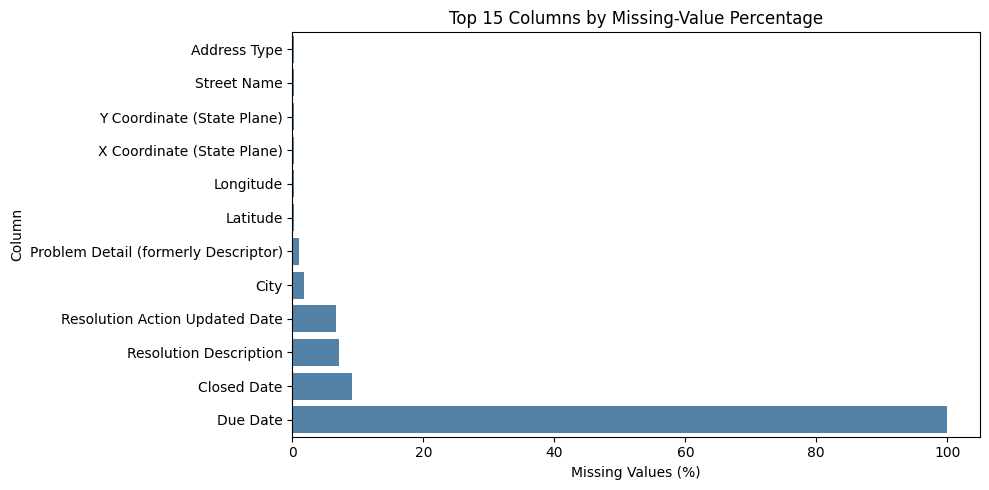

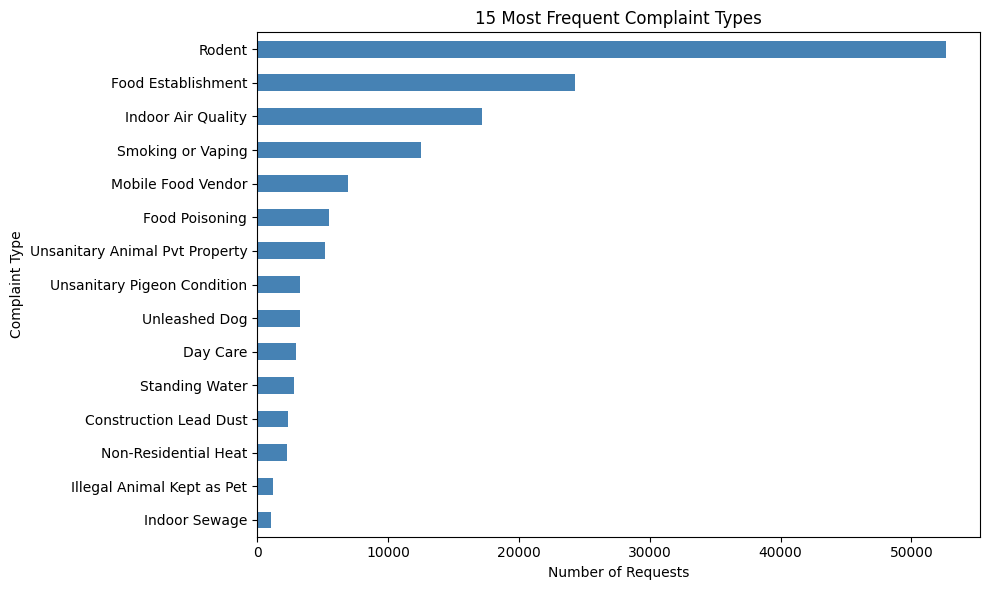

In [4]:
# Step 4: EDA - Missing values and common complaint types

# --------------------------------------------------
# 1. Visualize missing values
# --------------------------------------------------

# Calculate missing counts and percentages for each column
missing = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(2)
})

# Select the 15 columns with the highest missing percentages
missing_to_plot = (
    missing[missing["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
    .head(15)
    .sort_values("missing_percent")
)

# Plot missing-value percentages
plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_to_plot["missing_percent"],
    y=missing_to_plot.index,
    color="steelblue"
)

plt.title("Top 15 Columns by Missing-Value Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. Visualize common complaint types
# --------------------------------------------------

complaint_col = "Problem (formerly Complaint Type)"

# Count the 15 most frequent complaint categories
top_types = (
    data[complaint_col]
    .fillna("Missing")
    .value_counts()
    .head(15)
    .sort_values()
)

# Plot the most frequent complaint types
plt.figure(figsize=(10, 6))

top_types.plot(
    kind="barh",
    color="steelblue"
)

plt.title("15 Most Frequent Complaint Types")
plt.xlabel("Number of Requests")
plt.ylabel("Complaint Type")
plt.tight_layout()
plt.show()

### Step 4 — Results and Interpretation

The visual analysis revealed two main observations:

**1. Missing-value distribution**

- `Due Date` is entirely missing, confirming the finding from the initial data-quality audit.
- `Closed Date` has approximately 9.06% missing values, which may represent unresolved requests.
- `Resolution Description` and `Resolution Action Updated Date` also contain noticeable missing values.
- `City` and `Problem Detail` have relatively small amounts of missing information.
- Latitude, longitude, coordinates, street name, and address type have very low missing-value percentages.

These findings indicate that missingness is concentrated in specific columns rather than being widespread across the entire dataset.

**2. Complaint-type distribution**

- Rodent complaints are the most frequent category by a considerable margin.
- Food Establishment complaints are the second most frequent.
- Indoor Air Quality and Smoking or Vaping also represent substantial portions of the requests.
- The remaining categories have considerably fewer requests, indicating an uneven distribution of complaint types.

**Implications for preprocessing:**

- `Due Date` will be removed because it contains no available information.
- Missing `Closed Date` values will be retained for unresolved-request analysis and target construction.
- Missing values in selected input features will be handled during preprocessing.
- Complaint categories will be retained as categorical features, with appropriate encoding for the selected models.

No records or columns are removed or modified during this EDA step.

## Step 5 — EDA: Boroughs and Monthly Request Volume

Analyze the geographical and temporal distribution of DOHMH service requests.

This step examines:
- The number of requests reported in each borough.
- Monthly request volume to identify changes in complaint activity over time.

The creation date is also converted into datetime format to support temporal analysis and subsequent feature engineering.

Invalid or missing creation dates: 0
Creation date range: 2024-12-31 23:48:31 to 2026-10-06 02:02:21


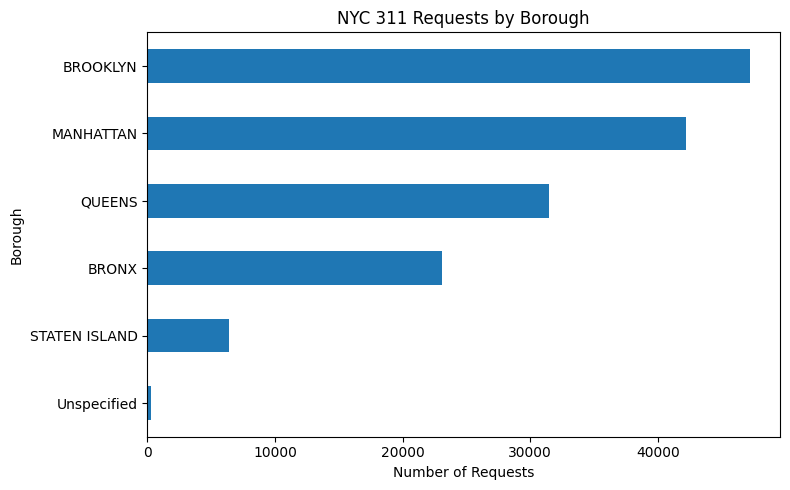

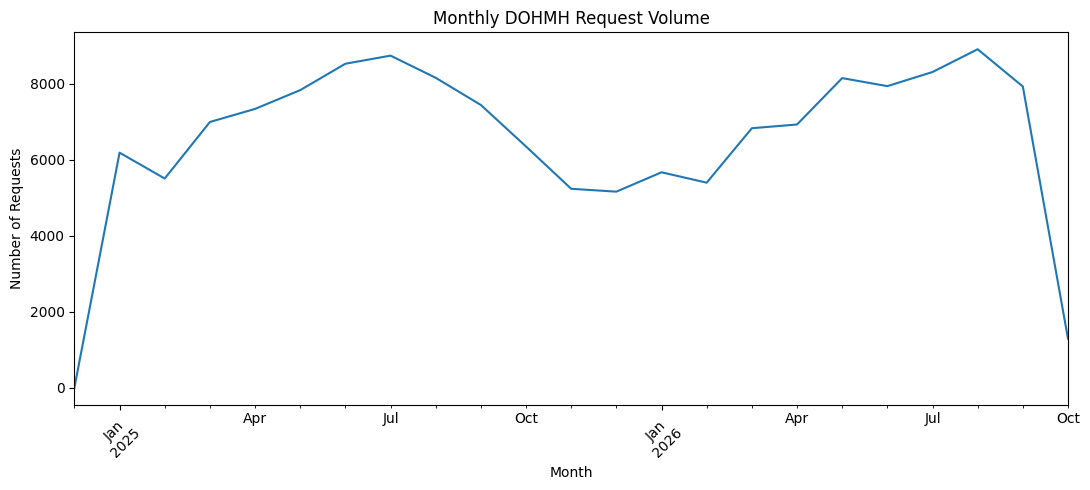

In [5]:
# Step 5: Analyze requests by borough and monthly volume

# 1. Convert Created Date into datetime format
created_col = "Created Date"

data[created_col] = pd.to_datetime(
    data[created_col],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

# Check for dates that could not be converted
print(
    "Invalid or missing creation dates:",
    data[created_col].isna().sum()
)

print(
    "Creation date range:",
    data[created_col].min(),
    "to",
    data[created_col].max()
)


# --------------------------------------------------
# 2. Analyze requests by borough
# --------------------------------------------------

# Count requests in each borough, including missing values
borough_counts = (
    data["Borough"]
    .fillna("Missing")
    .value_counts()
    .sort_values()
)

# Plot the geographical distribution
plt.figure(figsize=(8, 5))

borough_counts.plot(kind="barh")

plt.title("NYC 311 Requests by Borough")
plt.xlabel("Number of Requests")
plt.ylabel("Borough")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. Analyze monthly request volume
# --------------------------------------------------

# Exclude records with invalid creation dates for this plot only
monthly_data = data.dropna(subset=[created_col]).copy()

# Group requests by month of creation
monthly_volume = (
    monthly_data
    .set_index(created_col)
    .resample("MS")
    .size()
)

# Plot monthly request volume
plt.figure(figsize=(11, 5))

monthly_volume.plot()

plt.title("Monthly DOHMH Request Volume")
plt.xlabel("Month")
plt.ylabel("Number of Requests")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 5 — Results and Interpretation

The geographical and temporal analysis revealed the following observations:

**1. Requests by borough**

- Brooklyn recorded the highest number of DOHMH requests.
- Manhattan had the second-highest number of requests, followed by Queens and the Bronx.
- Staten Island had considerably fewer requests than the other boroughs.
- Only a very small number of requests had an unspecified borough.

This indicates that complaint volume is not distributed equally across the five boroughs.

**2. Monthly request volume**

- Monthly request volume fluctuated throughout the observation period.
- Request volume increased during the first half of 2025, reaching a high around June and July.
- A decline was observed during the later months of 2025.
- Request volume increased again during much of 2026, reaching another high around August.
- The final month, October 2026, contains incomplete data because the dataset ends on October 6.
- December 2024 also contains limited observations because the dataset begins on December 31.

**Implications:**

The geographical and monthly distributions show that complaint activity varies across locations and over time. These patterns support retaining borough and creation-time information as potential prediction features.

The incomplete months should be interpreted cautiously, as their request counts are not directly comparable with complete months.

No records or features are removed or modified during this EDA step.

## Step 6 — EDA: Closure Duration and Unresolved Requests

Analyze how long DOHMH complaints take to close and investigate requests that remain unresolved.

This step examines:

- The time between complaint creation and closure.
- The distribution of closure durations.
- The number of complaints closed within 7 days, between 8 and 30 days, and after 30 days.
- The relationship between complaint type and closure duration.
- Requests with missing closure dates and their observed age.

Closure duration is an outcome variable used for analysis and target construction. It will not be used as an input feature because the actual closure date is unknown when a new complaint is submitted.

Missing closure dates: 13652
Valid closure durations: 137035
Negative closure durations: 0
Same-day closures: 29769
Closures within 7 days: 77194
Closures after 7 and within 30 days: 15854
Closures after 30 days: 43987
Missing closure dates with at least 30 days observed: 9271

Mean closure duration (days): 21.73
Median closure duration (days): 3.33

Status distribution among requests with missing closure dates:


,count
Status,
In Progress,13646
Unspecified,6


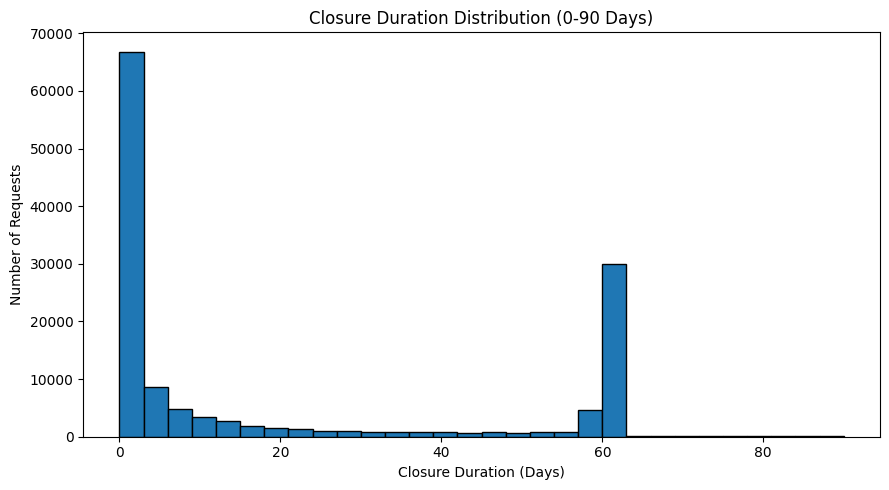

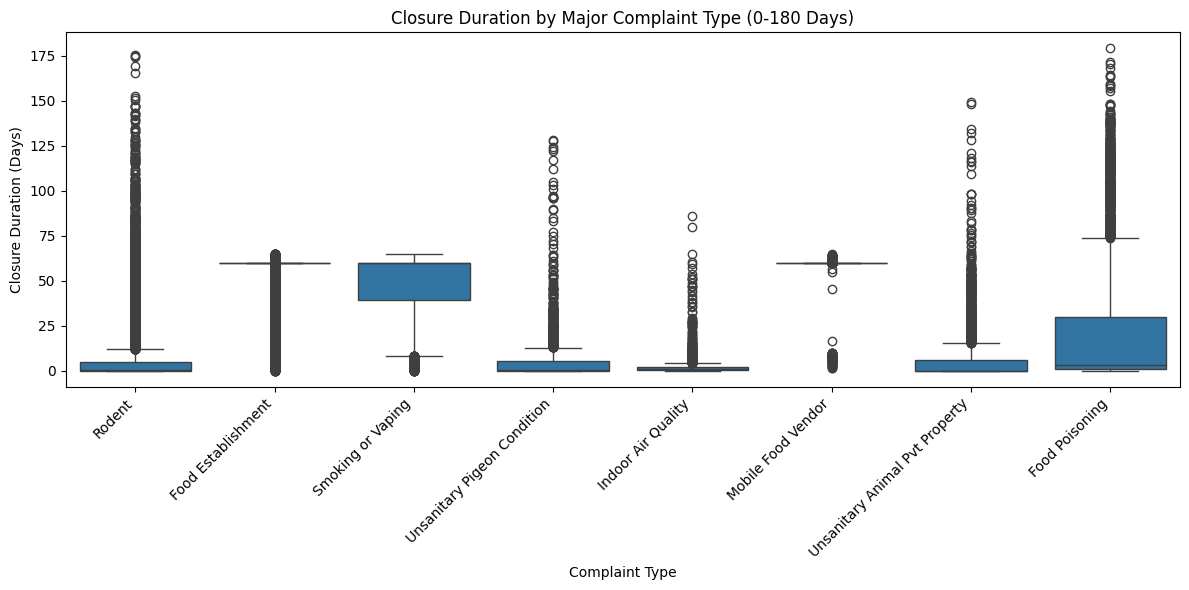

In [6]:
# Step 6: EDA - Closure duration and unresolved requests

created_col = "Created Date"
closed_col = "Closed Date"
complaint_col = "Problem (formerly Complaint Type)"

# --------------------------------------------------
# 1. Convert Closed Date to datetime
# --------------------------------------------------

# Created Date was already converted in Step 5.
data[closed_col] = pd.to_datetime(
    data[closed_col],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

# --------------------------------------------------
# 2. Calculate closure duration in days
# --------------------------------------------------

# Calculate the difference between closure and creation dates.
# Convert seconds into days by dividing by 86,400.
data["closure_duration_days_eda"] = (
    data[closed_col] - data[created_col]
).dt.total_seconds() / 86400

duration = data["closure_duration_days_eda"]

# Separate valid, non-negative closure durations.
valid_duration = duration[
    duration.notna() & duration.ge(0)
]

# --------------------------------------------------
# 3. Calculate observed age for unresolved requests
# --------------------------------------------------

# Calculate how long each complaint has been open,
# using the dataset observation date as the reference.
data["observation_age_days_eda"] = (
    OBSERVATION_DATE - data[created_col]
).dt.total_seconds() / 86400

# Identify records with missing closure dates.
missing_closure = data[closed_col].isna()

# Identify unresolved candidates observed for at least 30 days.
open_30_days = (
    missing_closure
    & data["observation_age_days_eda"].ge(30)
)

# --------------------------------------------------
# 4. Display closure-duration statistics
# --------------------------------------------------

print("Missing closure dates:", missing_closure.sum())

print("Valid closure durations:", len(valid_duration))

print("Negative closure durations:", duration.lt(0).sum())

print("Same-day closures:", valid_duration.eq(0).sum())

print("Closures within 7 days:", valid_duration.le(7).sum())

print(
    "Closures after 7 and within 30 days:",
    (valid_duration.gt(7) & valid_duration.le(30)).sum()
)

print("Closures after 30 days:", valid_duration.gt(30).sum())

print(
    "Missing closure dates with at least 30 days observed:",
    open_30_days.sum()
)

print("\nMean closure duration (days):",
      round(valid_duration.mean(), 2))

print("Median closure duration (days):",
      round(valid_duration.median(), 2))

# Inspect the status of requests with missing closure dates.
print("\nStatus distribution among requests with missing closure dates:")

display(
    data.loc[missing_closure, "Status"]
    .value_counts(dropna=False)
    .to_frame("count")
)

# --------------------------------------------------
# 5. Plot closure-duration distribution
# --------------------------------------------------

# Display durations between 0 and 90 days to improve visibility.
duration_90 = valid_duration[valid_duration.le(90)]

plt.figure(figsize=(9, 5))

plt.hist(
    duration_90,
    bins=30,
    edgecolor="black"
)

plt.title("Closure Duration Distribution (0-90 Days)")
plt.xlabel("Closure Duration (Days)")
plt.ylabel("Number of Requests")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Compare closure duration by complaint type
# --------------------------------------------------

# Select the eight most frequent complaint categories.
top_types = (
    data[complaint_col]
    .value_counts()
    .head(8)
    .index
)

# Keep valid durations up to 180 days for clearer comparison.
duration_by_type = data[
    data[complaint_col].isin(top_types)
    & data["closure_duration_days_eda"].between(0, 180)
].copy()

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=duration_by_type,
    x=complaint_col,
    y="closure_duration_days_eda"
)

plt.title("Closure Duration by Major Complaint Type (0-180 Days)")
plt.xlabel("Complaint Type")
plt.ylabel("Closure Duration (Days)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Step 6 — Results and Interpretation

The closure-duration analysis revealed the following findings:

**1. Closure-duration statistics**

- A total of 137,035 complaints had valid closure durations.
- No negative closure durations were identified.
- 29,769 complaints were closed on the same day they were created.
- 77,194 complaints were closed within 7 days.
- 15,854 complaints were closed after 7 and within 30 days.
- 43,987 complaints were closed after more than 30 days.
- The mean closure duration was 21.73 days, while the median was 3.33 days.

The difference between the mean and median indicates a right-skewed distribution, where some complaints take considerably longer to close than others.

**2. Unresolved requests**

A total of 13,652 complaints had missing closure dates:

- 13,646 were marked as `In Progress`.
- 6 had an `Unspecified` status.

Among the complaints with missing closure dates, 9,271 had been observed for at least 30 days.

These requests are important for distinguishing unresolved complaints from complaints that eventually close after 30 days.

**3. Closure duration by complaint type**

The boxplot shows differences in closure-duration distributions across the eight major complaint types.

- Some categories have relatively short typical closure durations.
- Smoking or Vaping shows a higher median closure duration than most of the other categories.
- Food Poisoning and Rodent complaints show substantial variation and numerous long-duration outliers.
- The distributions indicate that closure time differs across complaint categories.

**Implications for target construction:**

The findings support using four closure-outcome classes:

1. Closed within 7 days.
2. Closed after 7 and within 30 days.
3. Closed after more than 30 days.
4. Still open after at least 30 days of observation.

Complaints that remain open but have not yet reached 30 days of observation will retain an unknown target and will be excluded from supervised training.

Closure duration will be used for target construction and analysis, but excluded from model input features because it is not known when a new complaint is submitted.

## Step 7 — EDA: Repeated Complaints and Changing Categories

Investigate repeated service requests and changes in complaint-category distributions over time.

This analysis examines:

- Repeated requests associated with the same street and borough.
- The most frequently reported street and borough combinations.
- Changes in the monthly volume of the most common complaint categories.

The purpose is to understand whether certain locations experience recurring complaints and whether complaint patterns vary over time.

Repeated requests at the same location are treated as a measure of recurrence, not necessarily as duplicate complaints or reports of the exact same issue.

Monthly changes in complaint-category frequency indicate changes in category distributions, rather than confirmed reclassification of individual requests.

Top 10 street and borough combinations:


request_count
Borough   Street Name                     
MANHATTAN 2 AVENUE                    2105
          5 AVENUE                    1855
          BROADWAY                    1646
          AMSTERDAM AVENUE             957
QUEENS    JAMAICA AVENUE               948
BRONX     WOODYCREST AVENUE            798
MANHATTAN YORK AVENUE                  688
BRONX     GRAND CONCOURSE              677
MANHATTAN 1 AVENUE                     648
QUEENS    34 STREET                    643


Requests associated with locations having multiple reports: 148838
Percentage of requests at repeated locations: 99.0 %


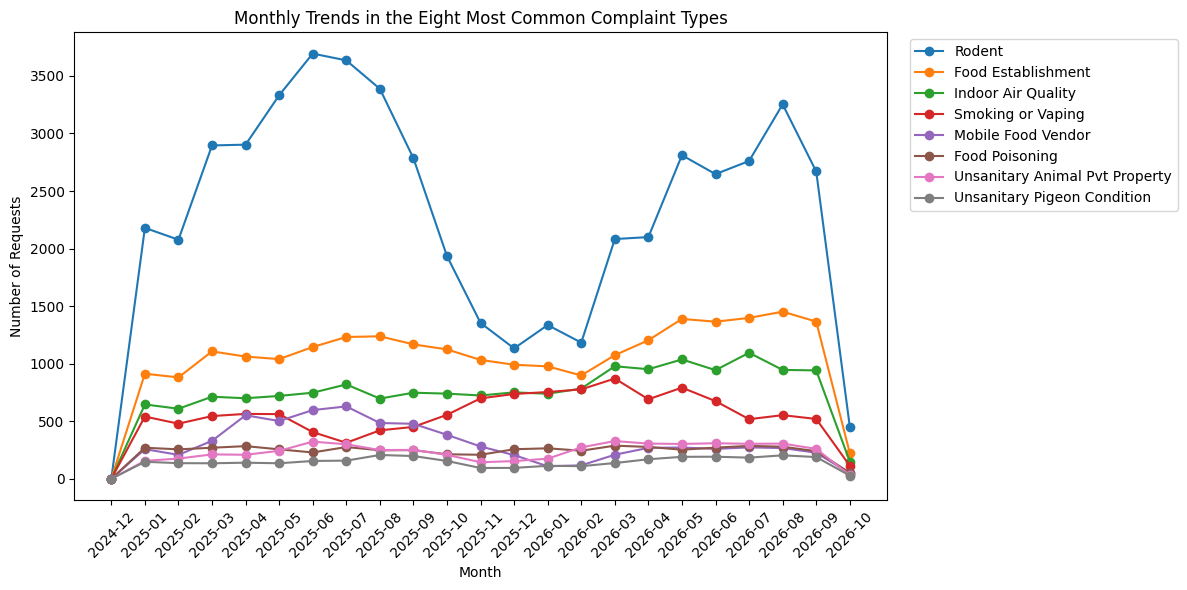

In [7]:
# Step 7: EDA - Repeated complaints and changing categories

# --------------------------------------------------
# 1. Analyze repeated requests by street and borough
# --------------------------------------------------

# Create a temporary copy to avoid modifying the original columns
recurring = data.copy()

# Standardize street names for consistent grouping
recurring["Street Name"] = (
    recurring["Street Name"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Remove records without street or borough information
recurring_locations = recurring.dropna(
    subset=["Street Name", "Borough"]
)

# Count requests for each street and borough combination
street_counts = (
    recurring_locations
    .groupby(["Borough", "Street Name"])
    .size()
    .sort_values(ascending=False)
)

# Display the ten most frequent combinations
print("Top 10 street and borough combinations:")

display(
    street_counts.head(10).to_frame("request_count")
)

# Calculate how many requests belong to locations
# that have more than one recorded request.
repeated_location_rows = (
    recurring_locations
    .groupby(["Borough", "Street Name"])["Unique Key"]
    .transform("size")
    .ge(2)
)

print(
    "\nRequests associated with locations having multiple reports:",
    repeated_location_rows.sum()
)

print(
    "Percentage of requests at repeated locations:",
    round(repeated_location_rows.mean() * 100, 2),
    "%"
)


# --------------------------------------------------
# 2. Analyze monthly complaint-category patterns
# --------------------------------------------------

# Extract the month of each complaint's creation
month_column = data[created_col].dt.to_period("M").astype(str)

# Select the eight most frequent complaint categories
top_categories = (
    data[complaint_col]
    .dropna()
    .value_counts()
    .head(8)
    .index
)

# Create a monthly frequency table
# Rows represent months and columns represent complaint categories.
type_month = pd.crosstab(
    month_column,
    data[complaint_col]
)

# Retain only the eight most common categories
type_month = type_month.reindex(
    columns=top_categories,
    fill_value=0
)

# Plot monthly trends for the selected categories
plt.figure(figsize=(12, 6))

for category in type_month.columns:
    plt.plot(
        type_month.index,
        type_month[category],
        marker="o",
        label=category
    )

plt.title("Monthly Trends in the Eight Most Common Complaint Types")
plt.xlabel("Month")
plt.ylabel("Number of Requests")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Step 7 — Results and Interpretation

The analysis of repeated complaints and changing category patterns revealed the following findings:

**1. Repeated complaints by location**

- The top 10 street and borough combinations show that certain locations receive a high number of service requests.
- The most frequent combination is 2 Avenue in Manhattan, with 2,105 requests, followed by 5 Avenue (1,855) and Broadway (1,646).
- Other frequently reported locations include Amsterdam Avenue (Manhattan), Jamaica Avenue (Queens), Woodycrest Avenue (Bronx), Grand Concourse (Bronx), and 34 Street (Queens).
- A total of 148,838 requests (99.0%) are associated with locations that have multiple reports.

This indicates that repeated requests at the same street and borough are very common in the dataset. However, multiple reports from the same location do not necessarily represent the same underlying issue.

**2. Monthly trends in major complaint types**

- Rodent complaints are consistently the most frequent category throughout the observation period.
- Food Establishment and Indoor Air Quality complaints are the next most common categories.
- Rodent complaints show noticeable fluctuations, with higher volumes during the middle of 2025 and again during the middle of 2026, and lower volumes toward the end of 2025.
- Food Establishment, Indoor Air Quality, and Smoking or Vaping also show fluctuations over time, with increases during parts of 2026.
- Other categories (Mobile Food Vendor, Food Poisoning, Unsanitary Animal Pvt Property, and Unsanitary Pigeon Condition) have lower and relatively more stable monthly counts.
- October 2026 contains incomplete data, explaining the sharp decrease across all categories. December 2024 also contains limited observations because the dataset begins on December 31.

The monthly trends indicate that complaint patterns vary over time and that the relative frequency of complaint categories changes across months.

**Implications for modeling**

- The high proportion of repeated requests suggests that the number of previous complaints at the same location could be a useful predictive feature.
- Certain locations may experience recurring issues, which may be associated with different closure-time outcomes.
- Monthly trends support the inclusion of time-based features, such as month and season.
- Complaint categories show different temporal patterns, which may help improve predictions when combined with location and time information.

No records or features are removed or modified during this EDA step.

## Step 8 — EDA: Numerical, Categorical, and Mixed-Type Associations

Investigate the relationships between numerical and categorical variables to identify potentially redundant features and understand how different characteristics of service requests are associated.

This step uses three statistical association methods:

**1. Pearson Correlation**
- Examines linear relationships between numerical variables.
- Measures both the strength and direction of the relationship.
- Values range from -1 to +1.

**2. Cramér's V**
- Measures the strength of association between pairs of categorical variables.
- Values range from 0 to 1, where higher values indicate stronger associations.

**3. Phi-K Correlation**
- Examines associations between numerical and categorical variables, as well as relationships within each variable type.
- Can capture both linear and nonlinear associations.
- Values range from 0 to 1, where higher values indicate stronger associations.

The three analyses provide complementary information to help identify overlapping features and guide subsequent feature-selection decisions.


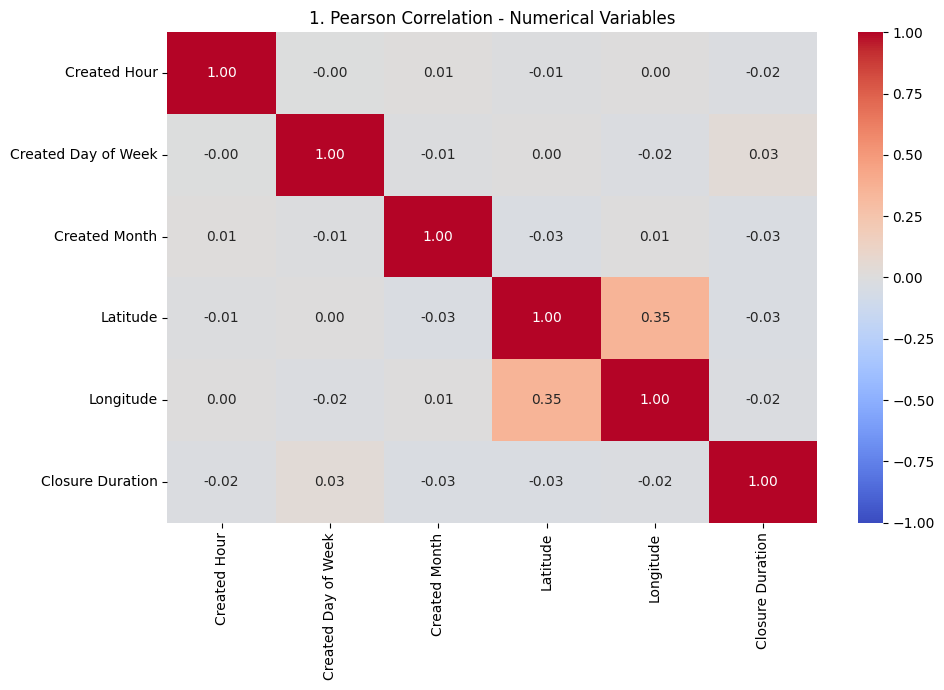

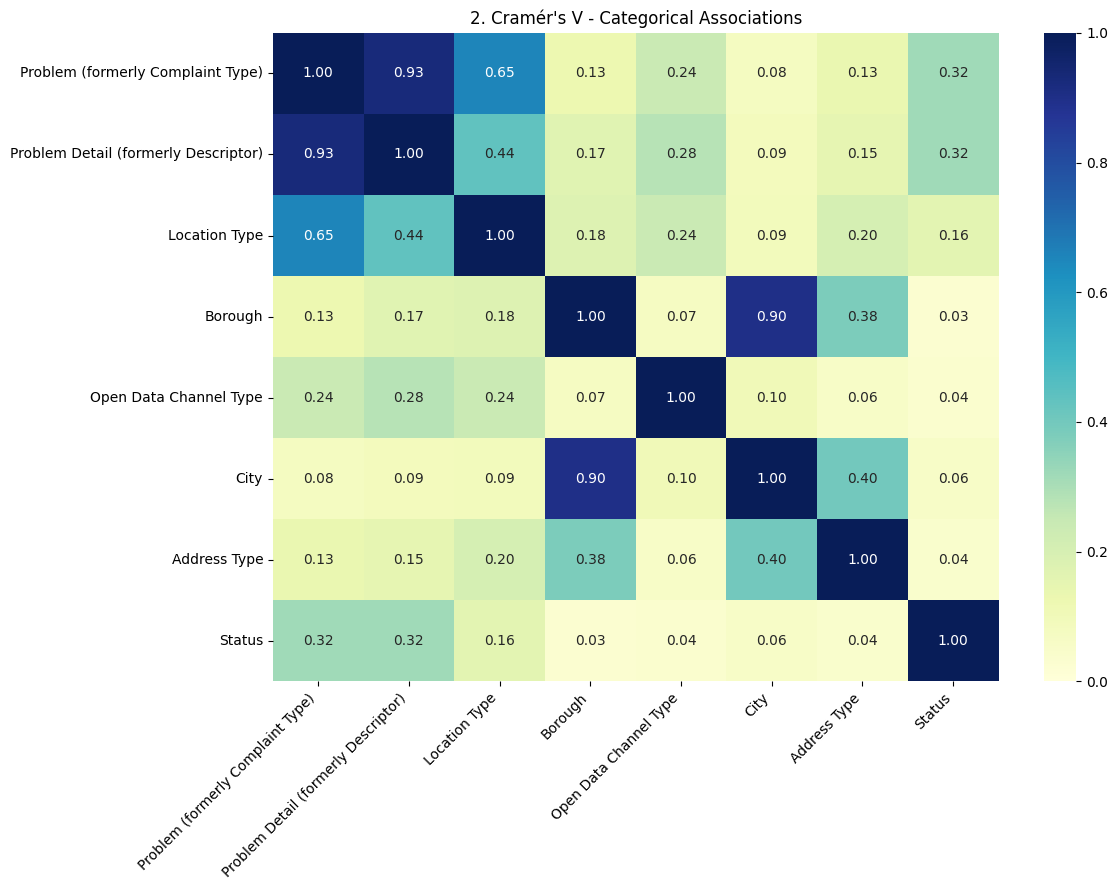

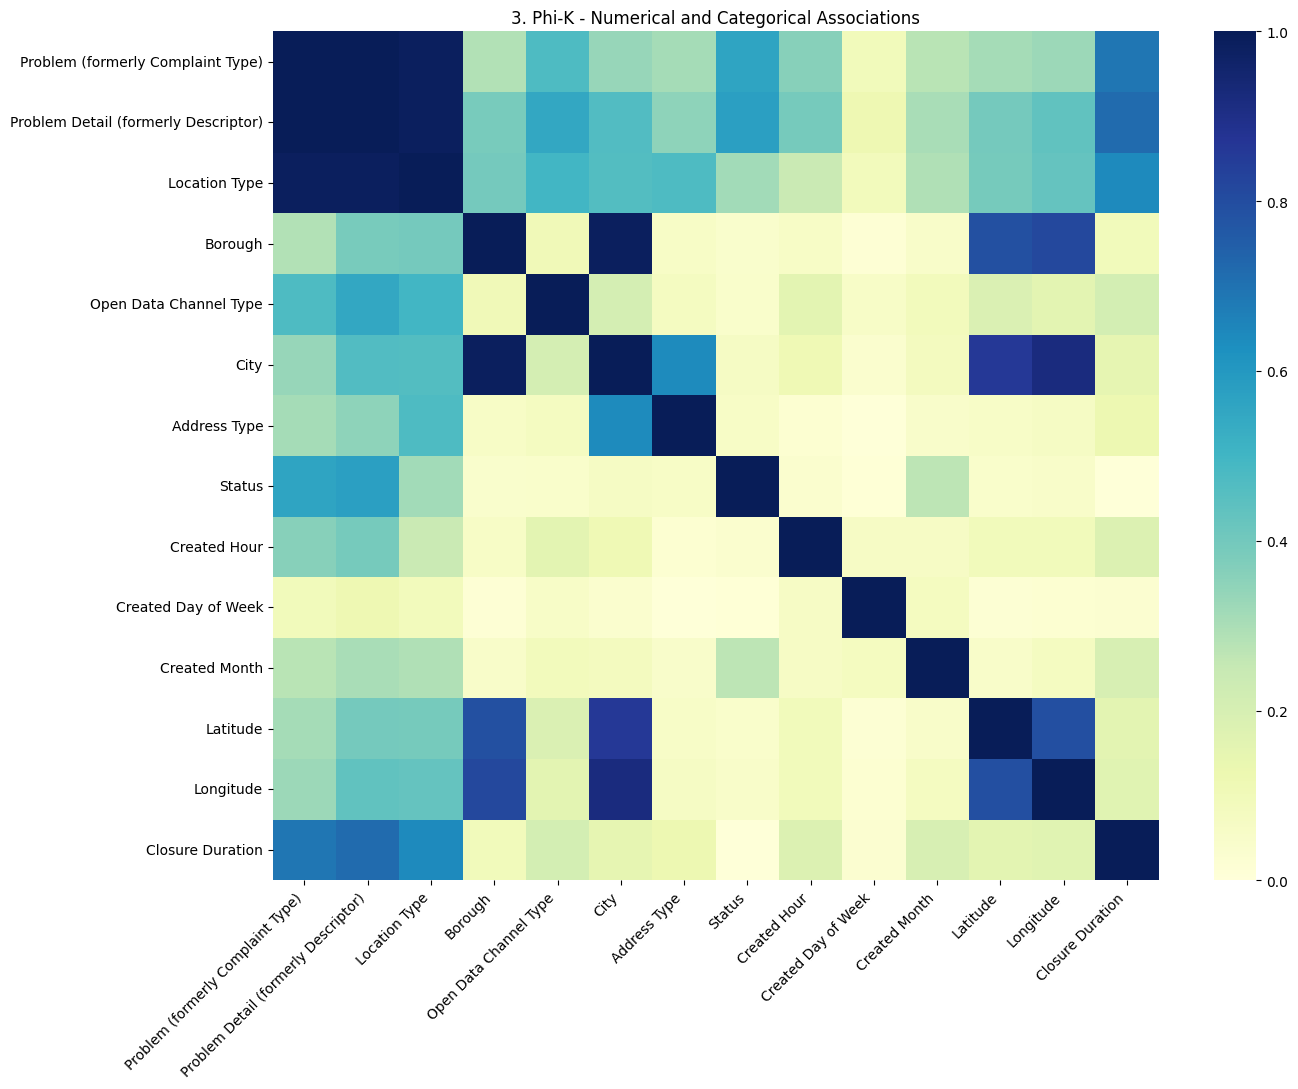

All three association heatmaps were created successfully.


In [8]:
# Step 8: Explore numerical, categorical, and mixed-type associations

# Install and import Phi-K
%pip -q install phik

import phik
from scipy.stats import chi2_contingency


# --------------------------------------------------
# 1. PEARSON: Numerical variables
# --------------------------------------------------

# Create a separate DataFrame for numerical analysis
numeric_data = pd.DataFrame(index=data.index)

# Extract time-based features from the creation date
dates = pd.to_datetime(data["Created Date"], errors="coerce")

numeric_data["Created Hour"] = dates.dt.hour
numeric_data["Created Day of Week"] = dates.dt.dayofweek
numeric_data["Created Month"] = dates.dt.month

# Include geographical coordinates
for col in ["Latitude", "Longitude"]:
    numeric_data[col] = pd.to_numeric(
        data[col], errors="coerce"
    )

# Include closure duration for EDA only
numeric_data["Closure Duration"] = pd.to_numeric(
    data["closure_duration_days_eda"],
    errors="coerce"
).where(
    data["closure_duration_days_eda"] >= 0
)

# Calculate Pearson correlation
pearson_corr = numeric_data.corr(method="pearson")

# Visualize numerical correlations
plt.figure(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("1. Pearson Correlation - Numerical Variables")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. CRAMÉR'S V: Categorical variables
# --------------------------------------------------

categorical_cols = [
    "Problem (formerly Complaint Type)",
    "Problem Detail (formerly Descriptor)",
    "Location Type",
    "Borough",
    "Open Data Channel Type",
    "City",
    "Address Type",
    "Status"
]

# Keep only columns available in the dataset
categorical_cols = [
    col for col in categorical_cols
    if col in data.columns
]


def cramers_v(x, y):
    """
    Calculate Cramér's V to measure the association
    between two categorical variables.
    """

    # Create a contingency table
    table = pd.crosstab(
        x.fillna("Missing").astype(str),
        y.fillna("Missing").astype(str)
    )

    # Check that both variables have at least two categories
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan

    # Calculate the chi-square statistic
    chi2 = chi2_contingency(
        table,
        correction=False
    )[0]

    n = table.to_numpy().sum()

    # Calculate the denominator
    denominator = n * min(
        table.shape[0] - 1,
        table.shape[1] - 1
    )

    if denominator == 0:
        return np.nan

    return np.sqrt(chi2 / denominator)


# Calculate Cramér's V for every pair of categorical variables
cramers_matrix = pd.DataFrame(
    np.nan,
    index=categorical_cols,
    columns=categorical_cols
)

for col1 in categorical_cols:
    for col2 in categorical_cols:

        if col1 == col2:
            cramers_matrix.loc[col1, col2] = 1.0

        else:
            cramers_matrix.loc[col1, col2] = cramers_v(
                data[col1],
                data[col2]
            )


# Visualize categorical associations
plt.figure(figsize=(12, 9))

sns.heatmap(
    cramers_matrix,
    annot=True,
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    fmt=".2f"
)

plt.title("2. Cramér's V - Categorical Associations")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. PHI-K: Numerical and categorical variables
# --------------------------------------------------

# Start with the categorical variables
mixed_data = data[categorical_cols].copy()

# Add the numerical variables
for col in numeric_data.columns:
    mixed_data[col] = numeric_data[col]

# Identify numerical columns for Phi-K
numeric_cols = numeric_data.columns.tolist()

# Calculate mixed-type associations
phik_matrix = mixed_data.phik_matrix(
    interval_cols=numeric_cols
)

# Visualize mixed-type associations
plt.figure(figsize=(14, 11))

sns.heatmap(
    phik_matrix,
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.title("3. Phi-K - Numerical and Categorical Associations")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Completion message
# --------------------------------------------------

print("All three association heatmaps were created successfully.")

### Step 8 — Results and Interpretation

The three association analyses revealed several important relationships between the dataset variables.

**1. Pearson Correlation — Numerical Variables**

- Most numerical variable pairs have correlations close to zero (approximately -0.03 to 0.03), indicating very weak linear relationships.
- Latitude and longitude have a positive correlation of **0.35**, indicating a moderate positive linear relationship.
- Creation hour, day of week, and month show very weak linear correlations with closure duration.

**Preprocessing decision:**

Retain the creation-time features for further analysis. Initially retain latitude and longitude as one geographical feature pair. Their usefulness will be evaluated during modeling.

**2. Cramér's V — Categorical Variables**

The strongest associations include:

- Problem Type and Problem Detail (**0.93**), indicating a very strong association.
- Borough and City (**0.90**), indicating a very strong association.
- Problem Type and Location Type (**0.65**), indicating a relatively strong association.
- Problem Detail and Location Type (**0.44**).
- City and Address Type (**0.40**).
- Borough and Address Type (**0.38**).

Other variables show weaker associations.

**Preprocessing decision:**

- Retain Problem Type and remove Problem Detail from the initial modeling features because of their substantial information overlap.
- Retain Borough and exclude City because they provide strongly overlapping geographical information.
- Exclude Address Type because it provides limited additional information and is dominated by the ADDRESS category.
- Retain Location Type and Open Data Channel Type for further modeling evaluation.

**3. Phi-K — Mixed-Type Associations**

The Phi-K heatmap provides additional information about relationships between numerical and categorical variables.

- Complaint Type, Problem Detail, and Location Type show noticeable associations with one another.
- Borough and City show a strong geographical association.
- Latitude and Longitude show noticeable associations with geographical categories.
- Closure Duration shows noticeable associations with complaint-related variables.
- Creation-time features generally show weaker associations with most categorical variables.

These findings complement the Pearson and Cramér's V analyses by considering mixed-type relationships and potentially nonlinear associations.

**Note:** Closure Duration and Status are included for exploratory analysis only. Neither will be used as an input feature because they contain information that is unavailable at complaint submission.

**Overall feature-selection decisions:**

The association analysis supports the following initial decisions:

- Retain Problem Type.
- Remove Problem Detail.
- Retain Location Type.
- Retain Borough and remove City.
- Retain Open Data Channel Type.
- Exclude Address Type.
- Initially retain Latitude and Longitude.
- Retain creation-time features.
- Exclude Status and Closure Duration from model inputs.

These decisions provide an initial feature-selection strategy. Final feature usefulness will be assessed during model development.

## Step 9 — EDA Summary and Preprocessing Decisions

The exploratory data analysis provided insights into the geographical distribution, complaint patterns, closure durations, repeated requests, and relationships between features.

Based on the findings, the following preprocessing decisions were established:

**1. Data Quality**
- Retain all 150,687 DOHMH records.
- No exact duplicate records or repeated complaint IDs were identified.
- Remove `Due Date` because it is entirely empty.
- Remove `Agency Name` because it is constant across all records.

**2. Missing Values**
- Retain records with missing `Closed Date` because they may represent unresolved requests.
- Investigate the six requests with unspecified status.
- Handle missing values in selected input features during preprocessing.

**3. Feature Selection**

The association analyses identified potentially redundant variables.

- Retain `Problem (formerly Complaint Type)` and remove `Problem Detail (formerly Descriptor)` because of their very strong association.
- Retain `Borough` and remove `City` because of their very strong geographical association.
- Exclude `Address Type` from the initial modeling features.
- Retain `Location Type` and `Open Data Channel Type`.
- Initially retain `Latitude` and `Longitude` as geographical features.
- Retain creation-time information, including hour, day of week, and month.
- Exclude `Status`, closure dates, resolution descriptions, and closure duration from model inputs because they contain information unavailable at complaint submission or information derived after submission.

**4. Repeated Complaints**
- Repeated requests at the same street and borough are common.
- Retain the information needed to engineer a previous-request count feature.
- Calculate previous requests using earlier complaints only.

**5. Prediction Target**

The project will use multiclass classification with four closure outcomes:

1. Closed within 7 days.
2. Closed after 7 and within 30 days.
3. Closed after 30 days.
4. Still open after at least 30 days of observation.

Requests without sufficient observation time will retain an unknown target and will not be used for supervised training.

These decisions will guide the subsequent cleaning, feature engineering, and modeling preparation stages.

## Step 10 — Data Cleaning and Column Standardization

Perform basic cleaning to prepare the dataset for feature engineering and modeling.

This step includes:

- Standardizing column names into lowercase snake_case format.
- Removing exact duplicate records, if present.
- Removing columns that contain no useful information, including entirely empty and constant columns identified during EDA.
- Preserving the complaint identifier for record tracking.
- Creating a column mapping to document the relationship between original and standardized column names, including removed columns and their removal reasons.

The complete retained dataset will be preserved without restricting its creation-date range.

In [9]:
# Step 10: Standardize columns and perform basic cleaning

import re

# --------------------------------------------------
# 1. Create a mapping of original column names
# --------------------------------------------------

original_columns = data.columns.tolist()

# Convert column names into lowercase snake_case
standardized_columns = [
    re.sub(
        r"_+",
        "_",
        re.sub(r"[^a-z0-9]+", "_", col.lower())
    ).strip("_")
    for col in original_columns
]

# Create a mapping between original and standardized names
column_map = pd.DataFrame({
    "original_column": original_columns,
    "standardized_column": standardized_columns
})

# Apply standardized column names
data.columns = standardized_columns

print("Column names standardized successfully.")

# --------------------------------------------------
# 2. Remove exact duplicate records
# --------------------------------------------------

duplicates_before = data.duplicated().sum()

# Remove exact duplicate rows
data = data.drop_duplicates().copy()

duplicates_removed = duplicates_before

print("\nExact duplicate rows removed:", duplicates_removed)

# --------------------------------------------------
# 3. Remove empty and constant columns
# --------------------------------------------------

# These columns were identified during the earlier EDA
columns_to_remove = {
    "due_date": "Entirely empty column",
    "agency_name": "Constant column; all records belong to DOHMH"
}

# Keep only columns that currently exist
columns_to_remove = {
    col: reason
    for col, reason in columns_to_remove.items()
    if col in data.columns
}

# Record the removal decisions in the column map
column_map["removal_reason"] = column_map[
    "standardized_column"
].map(columns_to_remove)

# Remove the selected columns
data = data.drop(
    columns=list(columns_to_remove.keys())
)

print("\nRemoved columns:")

for col, reason in columns_to_remove.items():
    print(f"- {col}: {reason}")

# --------------------------------------------------
# 4. Update the column mapping
# --------------------------------------------------

column_map["retained"] = ~column_map[
    "standardized_column"
].isin(columns_to_remove)

# Save the mapping for documentation
column_map.to_csv(
    os.path.join(ARTIFACT_DIR, "nyc311_column_map.csv"),
    index=False
)

# --------------------------------------------------
# 5. Inspect the cleaned dataset
# --------------------------------------------------

print("\nCleaned dataset shape:", data.shape)

print("\nStandardized column names:")
print(data.columns.tolist())

print("\nRemaining missing values:")
display(
    data.isna().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
    .query("missing_count > 0")
)

print("\nRemaining exact duplicates:", data.duplicated().sum())

print("\nColumn mapping:")
display(column_map)

print("\nStep 10 completed successfully.")

Column names standardized successfully.

Exact duplicate rows removed: 0

Removed columns:
- due_date: Entirely empty column
- agency_name: Constant column; all records belong to DOHMH

Cleaned dataset shape: (150687, 20)

Standardized column names:
['unique_key', 'created_date', 'closed_date', 'problem_formerly_complaint_type', 'problem_detail_formerly_descriptor', 'location_type', 'street_name', 'address_type', 'city', 'status', 'resolution_description', 'resolution_action_updated_date', 'borough', 'x_coordinate_state_plane', 'y_coordinate_state_plane', 'open_data_channel_type', 'latitude', 'longitude', 'closure_duration_days_eda', 'observation_age_days_eda']

Remaining missing values:


,missing_count
closed_date,13652
closure_duration_days_eda,13652
resolution_description,10640
resolution_action_updated_date,9962
city,2660
problem_detail_formerly_descriptor,1627
longitude,462
latitude,462
x_coordinate_state_plane,458
y_coordinate_state_plane,437



Remaining exact duplicates: 0

Column mapping:


,original_column,standardized_column,removal_reason,retained
0,Unique Key,unique_key,NaN,True
1,Created Date,created_date,NaN,True
2,Closed Date,closed_date,NaN,True
3,Agency Name,agency_name,Constant column; all records belong to DOHMH,False
4,Problem (formerly Complaint Type),problem_formerly_complaint_type,NaN,True
5,Problem Detail (formerly Descriptor),problem_detail_formerly_descriptor,NaN,True
6,Location Type,location_type,NaN,True
7,Street Name,street_name,NaN,True
8,Address Type,address_type,NaN,True
9,City,city,NaN,True



Step 10 completed successfully.


### Step 10 — Results and Interpretation

The basic data-cleaning operations were completed successfully.

**1. Column standardization**
- All column names were converted into lowercase snake_case format.
- A column mapping was created to preserve the relationship between original and standardized names.

**2. Duplicate removal**
- No exact duplicate records were identified.
- Therefore, no records were removed during duplicate cleaning.

**3. Column removal**
Two columns were removed based on the EDA findings:
- `due_date`: Removed because all 150,687 values were missing.
- `agency_name`: Removed because all records belonged to the Department of Health and Mental Hygiene.

**4. Remaining missing values**

Several columns still contain missing values:
- `closed_date`: 13,652 missing values.
- `resolution_description`: 10,640 missing values.
- `resolution_action_updated_date`: 9,962 missing values.
- `city`: 2,660 missing values.
- `problem_detail_formerly_descriptor`: 1,627 missing values.
- Geographical coordinates and street-related fields contain relatively small amounts of missing information.

These missing values will be handled according to their roles during subsequent preprocessing.

**5. Final dataset**

The cleaned dataset contains 150,687 records and 20 columns. No records were removed during this cleaning step.

The complaint identifier `unique_key` is retained for record tracking but will not be used as a model input.

The EDA-derived columns `closure_duration_days_eda` and `observation_age_days_eda` will be used for target construction and analysis, not as prediction features.

## Step 11 — Target Construction: Four Closure-Time Categories

Construct the target variable `closure_time_category` using the complaint creation date, closure date, and current request status.

The prediction task is multiclass classification with four mutually exclusive classes:

1. `closed_within_7_days`: Requests closed within 7 days.
2. `closed_after_7_within_30_days`: Requests closed after 7 days and within 30 days.
3. `closed_after_30_days`: Requests closed after more than 30 days.
4. `open`: Requests that have not been closed at the time of the dataset snapshot, regardless of how long they have been open.

Closure duration is calculated by subtracting the creation date from the closure date.

Requests without a recorded closure date are assigned to the open class, based on the assumption that a missing closure date indicates that the request remains open in the available dataset.

Records with invalid or insufficient date information retain an unknown target.

The target is used for supervised classification, while closure dates and closure durations will be excluded from model input features.

In [11]:
# Step 11: Create the four-class closure target

# --------------------------------------------------
# 1. Ensure date columns have the correct format
# --------------------------------------------------

data["created_date"] = pd.to_datetime(
    data["created_date"],
    errors="coerce"
)

data["closed_date"] = pd.to_datetime(
    data["closed_date"],
    errors="coerce"
)

# --------------------------------------------------
# 2. Calculate closure duration
# --------------------------------------------------

# Calculate closure time in days for closed requests
data["closure_duration_days"] = (
    data["closed_date"] - data["created_date"]
).dt.total_seconds() / 86400

duration = data["closure_duration_days"]

# --------------------------------------------------
# 3. Initialize the target
# --------------------------------------------------

# Start with unknown labels
data["closure_time_category"] = pd.Series(
    pd.NA,
    index=data.index,
    dtype="string"
)

# Identify records with valid creation dates
valid_created = data["created_date"].notna()

# Identify closed requests with valid dates
valid_closed = (
    valid_created
    & data["closed_date"].notna()
    & duration.notna()
    & duration.ge(0)
)

# Identify requests without a recorded closure date
# These are treated as open in the dataset snapshot
valid_open = (
    valid_created
    & data["closed_date"].isna()
)

# --------------------------------------------------
# 4. Assign the four target classes
# --------------------------------------------------

# Class 1: Closed within 7 days
data.loc[
    valid_closed & duration.le(7),
    "closure_time_category"
] = "closed_within_7_days"

# Class 2: Closed after 7 and within 30 days
data.loc[
    valid_closed & duration.gt(7) & duration.le(30),
    "closure_time_category"
] = "closed_after_7_within_30_days"

# Class 3: Closed after 30 days
data.loc[
    valid_closed & duration.gt(30),
    "closure_time_category"
] = "closed_after_30_days"

# Class 4: All requests without a recorded closure date
# No minimum observation period is required
data.loc[
    valid_open,
    "closure_time_category"
] = "open"

# --------------------------------------------------
# 5. Display target distribution
# --------------------------------------------------

print("Four-class target distribution:")

class_counts = (
    data["closure_time_category"]
    .value_counts()
    .reindex(CLASS_NAMES[:3] + ["open"], fill_value=0)
)

target_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": (
        class_counts / len(data) * 100
    ).round(2)
})

display(target_summary)

# --------------------------------------------------
# 6. Check known and unknown targets
# --------------------------------------------------

known_targets = data["closure_time_category"].notna()

print("\nTotal records:", len(data))
print("Records with known targets:", known_targets.sum())
print("Records with unknown targets:", (~known_targets).sum())

print(
    "Percentage with known targets:",
    round(known_targets.mean() * 100, 2),
    "%"
)

# --------------------------------------------------
# 7. Validate target construction
# --------------------------------------------------

print("\nTarget validation:")

print(
    "Open requests assigned to Class 4:",
    (data["closure_time_category"] == "open").sum()
)

print(
    "Negative closure durations:",
    duration.lt(0).sum()
)

print(
    "Requests with missing closure dates:",
    data["closed_date"].isna().sum()
)

print(
    "Requests with invalid creation dates:",
    data["created_date"].isna().sum()
)

# Inspect statuses of requests classified as open
print("\nStatus distribution among open requests:")

display(
    data.loc[valid_open, "status"]
    .value_counts(dropna=False)
    .to_frame("count")
)

print("\nTarget construction completed successfully.")

Four-class target distribution:


,count,percentage
closure_time_category,,
closed_within_7_days,77194,51.23
closed_after_7_within_30_days,15854,10.52
closed_after_30_days,43987,29.19
open,13652,9.06



Total records: 150687
Records with known targets: 150687
Records with unknown targets: 0
Percentage with known targets: 100.0 %

Target validation:
Open requests assigned to Class 4: 13652
Negative closure durations: 0
Requests with missing closure dates: 13652
Requests with invalid creation dates: 0

Status distribution among open requests:


,count
status,
In Progress,13646
Unspecified,6



Target construction completed successfully.


### Step 11 — Results and Interpretation

The four-class target was successfully constructed using complaint closure duration and closure-date availability.

**1. Target distribution**

All 150,687 records received a target label:

- **Closed within 7 days:** 77,194 requests (51.23%).
- **Closed after 7 and within 30 days:** 15,854 requests (10.52%).
- **Closed after 30 days:** 43,987 requests (29.19%).
- **Open:** 13,652 requests (9.06%).

The results show that requests closed within 7 days represent the largest class, while requests closed after 7 and within 30 days represent the smallest class.


## Step 12 — Feature Engineering: Create Prediction-Time Features

Create additional features using information available when a service request is submitted.

The engineered features include:

- `created_hour`: Hour when the complaint was submitted.
- `created_day_of_week`: Day of the week when the complaint was submitted.
- `created_month`: Month when the complaint was submitted.
- `created_is_weekend`: Indicates whether the complaint was submitted during the weekend.
- `prior_requests_same_street_borough`: Number of requests submitted at strictly earlier timestamps on the same street and in the same borough.

These features are intended to capture temporal patterns and repeated complaint activity.

The historical request count will be calculated using only earlier requests, ensuring that the current complaint does not contribute to its own historical count.

Missing location information will be retained and handled during the subsequent preprocessing stage.

In [12]:
# Step 12: Create prediction-time features

# --------------------------------------------------
# 1. Create features from the complaint creation date
# --------------------------------------------------

# Extract the hour of complaint submission
data["created_hour"] = data["created_date"].dt.hour

# Extract the day of the week (Monday=0, Sunday=6)
data["created_day_of_week"] = (
    data["created_date"].dt.dayofweek
)

# Extract the month of complaint submission
data["created_month"] = data["created_date"].dt.month

# Identify weekend submissions (Saturday=5, Sunday=6)
data["created_is_weekend"] = (
    data["created_day_of_week"]
    .isin([5, 6])
    .astype("Int64")
)


# --------------------------------------------------
# 2. Create the historical recurrence feature
# --------------------------------------------------

# Initialize the feature with missing values
data["prior_requests_same_street_borough"] = np.nan

# Select records with valid creation dates and location information
valid_rows = data.loc[
    data["created_date"].notna()
    & data["street_name"].notna()
    & data["borough"].notna()
].copy()

# Standardize street names for consistent matching
valid_rows["_street_normalized"] = (
    valid_rows["street_name"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Exclude empty street names
valid_rows = valid_rows[
    valid_rows["_street_normalized"].ne("")
].copy()

# Preserve original row indices
valid_rows["_row_index"] = valid_rows.index

# Count requests at each exact creation timestamp
time_counts = (
    valid_rows
    .groupby(
        ["borough", "_street_normalized", "created_date"]
    )
    .size()
    .reset_index(name="requests_at_same_time")
)

# Sort requests chronologically within each location
time_counts = time_counts.sort_values(
    ["borough", "_street_normalized", "created_date"]
)

# Count requests submitted at strictly earlier timestamps
time_counts["prior_count"] = (
    time_counts
    .groupby(["borough", "_street_normalized"])["requests_at_same_time"]
    .cumsum()
    - time_counts["requests_at_same_time"]
)

# Attach historical counts to the original records
valid_rows = valid_rows.merge(
    time_counts[
        [
            "borough",
            "_street_normalized",
            "created_date",
            "prior_count"
        ]
    ],
    on=[
        "borough",
        "_street_normalized",
        "created_date"
    ],
    how="left"
)

# Assign the calculated counts using the original row indices
data.loc[
    valid_rows["_row_index"],
    "prior_requests_same_street_borough"
] = valid_rows["prior_count"].to_numpy()


# --------------------------------------------------
# 3. Inspect the engineered features
# --------------------------------------------------

time_features = [
    "created_hour",
    "created_day_of_week",
    "created_month",
    "created_is_weekend",
    "prior_requests_same_street_borough"
]

print("Created prediction-time features:")

display(data[time_features].head(10))

# Display descriptive statistics
print("\nFeature statistics:")

display(data[time_features].describe().T)

# Check missing historical recurrence counts
print(
    "\nRows without a usable historical recurrence count:",
    data["prior_requests_same_street_borough"].isna().sum()
)

print("\nFeature engineering completed successfully.")

Created prediction-time features:


,created_hour,created_day_of_week,created_month,created_is_weekend,prior_requests_same_street_borough
0,23,1,12,0,0.0
1,23,1,12,0,0.0
2,0,2,1,0,0.0
3,0,2,1,0,1.0
4,0,2,1,0,0.0
5,0,2,1,0,0.0
6,1,2,1,0,0.0
7,1,2,1,0,0.0
8,1,2,1,0,0.0
9,1,2,1,0,0.0



Feature statistics:


,count,mean,std,min,25%,50%,75%,max
created_hour,150687.0,13.232966,5.66152,0.0,10.0,13.0,18.0,23.0
created_day_of_week,150687.0,2.71975,1.928188,0.0,1.0,3.0,4.0,6.0
created_month,150687.0,5.974265,2.970516,1.0,4.0,6.0,8.0,12.0
created_is_weekend,150687.0,0.214365,0.410382,0.0,0.0,0.0,0.0,1.0
prior_requests_same_street_borough,150338.0,102.131936,226.456532,0.0,8.0,28.0,88.0,2104.0



Rows without a usable historical recurrence count: 349

Feature engineering completed successfully.


### Step 12 — Results and Interpretation

The feature-engineering process successfully created five additional prediction-time features.

**1. Temporal Features**

Four features were extracted from the complaint creation date:

- `created_hour`: Represents the hour of submission, ranging from 0 to 23.
- `created_day_of_week`: Represents the day of submission, ranging from 0 (Monday) to 6 (Sunday).
- `created_month`: Represents the month of submission, ranging from 1 to 12.
- `created_is_weekend`: Indicates whether a complaint was submitted during the weekend.

All four features were successfully generated without missing values.

The weekend indicator has a mean of approximately 0.214, indicating that around 21.4% of requests were submitted on Saturdays or Sundays.

**2. Historical Recurrence Feature**

The feature `prior_requests_same_street_borough` measures the number of requests submitted at strictly earlier timestamps on the same street and within the same borough.

Its descriptive statistics revealed:

- Mean: 102.13 previous requests.
- Median: 28 previous requests.
- 25th percentile: 8 requests.
- 75th percentile: 88 requests.
- Maximum: 2,104 previous requests.

The difference between the mean and median indicates a highly right-skewed distribution. Some street-and-borough combinations have substantially more historical requests than others.

**3. Missing Historical Counts**

A total of 349 records had no usable historical recurrence count because the required street or borough information was unavailable.

These missing values will be handled during the preprocessing stage rather than removing the corresponding records.

**4. Implications for Modeling**

- Creation-time features may capture temporal patterns associated with complaint closure outcomes.
- The historical recurrence feature may help investigate whether locations with repeated service requests experience different closure outcomes.
- The highly skewed recurrence distribution will be considered during numerical preprocessing.
- Missing historical counts will be imputed using the training data during model preparation.

**Decision:** Retain all five engineered features as potential model inputs. Their usefulness will be evaluated during model development.

## Step 13 — Final Data Quality Checks and Save the Master Dataset

Perform final checks on the cleaned dataset, engineered features, and four-class target before saving the master dataset.

Verify the dataset dimensions, target distribution, duplicate records, and remaining missing values.

Save the complete dataset, including the target and engineered features, as a CSV file for subsequent splitting and model-specific preprocessing.

In [13]:
# Step 13: Final checks and save the master dataset

# --------------------------------------------------
# 1. Update the final target class names
# --------------------------------------------------

CLASS_NAMES = [
    "closed_within_7_days",
    "closed_after_7_within_30_days",
    "closed_after_30_days",
    "open"
]

# --------------------------------------------------
# 2. Create the final master dataset
# --------------------------------------------------

master = data.copy()

# --------------------------------------------------
# 3. Verify dataset structure
# --------------------------------------------------

print("Master dataset shape:", master.shape)

print("\nTotal records:", len(master))
print("Total columns:", len(master.columns))

# --------------------------------------------------
# 4. Check target distribution
# --------------------------------------------------

print("\nTarget distribution:")

target_counts = (
    master["closure_time_category"]
    .value_counts(dropna=False)
)

display(target_counts.to_frame("count"))

# --------------------------------------------------
# 5. Check data quality
# --------------------------------------------------

print("\nExact duplicate rows:", master.duplicated().sum())

print(
    "Duplicate complaint IDs:",
    master["unique_key"].duplicated().sum()
)

print(
    "Unknown target values:",
    master["closure_time_category"].isna().sum()
)

# --------------------------------------------------
# 6. Check missing values
# --------------------------------------------------

print("\nColumns with missing values:")

missing_summary = pd.DataFrame({
    "missing_count": master.isna().sum(),
    "missing_percentage": (
        master.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary[
        missing_summary["missing_count"] > 0
    ].sort_values(
        "missing_percentage",
        ascending=False
    )
)

# --------------------------------------------------
# 7. Save the complete master dataset
# --------------------------------------------------

master.to_csv(MASTER_FILE, index=False)

print("\nMaster dataset saved successfully:", MASTER_FILE)

print("\nStep 13 completed successfully.")

Master dataset shape: (150687, 28)

Total records: 150687
Total columns: 28

Target distribution:


,count
closure_time_category,
closed_within_7_days,77194
closed_after_30_days,43987
closed_after_7_within_30_days,15854
open,13652



Exact duplicate rows: 0
Duplicate complaint IDs: 0
Unknown target values: 0

Columns with missing values:


,missing_count,missing_percentage
closed_date,13652,9.06
closure_duration_days,13652,9.06
closure_duration_days_eda,13652,9.06
resolution_description,10640,7.06
resolution_action_updated_date,9962,6.61
city,2660,1.77
problem_detail_formerly_descriptor,1627,1.08
latitude,462,0.31
longitude,462,0.31
x_coordinate_state_plane,458,0.30



Master dataset saved successfully: nyc311_master.csv

Step 13 completed successfully.


### Step 13 — Results and Interpretation

The final master dataset contains **150,687 records and 28 columns**.

- All four target classes are present, with no unknown target values.
- No exact duplicate records or duplicate complaint identifiers were found.
- Missing values remain in selected columns and will be handled during model-specific preprocessing.
- The complete master dataset was successfully saved as `nyc311_master.csv`.

**Decision:** Retain the complete master dataset for feature selection and subsequent modeling preparation.

## Step 14 — Select model features and target

Select features that would be available when a complaint is submitted. Keep identifiers and post-submission information in the master dataset for analysis, but exclude them from model inputs. Rows with unknown target labels remain in the master dataset and are excluded from supervised modeling.

In [14]:
# Step 14: Select model features and target

# --------------------------------------------------
# 1. Define the prediction target
# --------------------------------------------------

TARGET = "closure_time_category"

# --------------------------------------------------
# 2. Select categorical features
# --------------------------------------------------

categorical_features = [
    "problem_formerly_complaint_type",
    "location_type",
    "borough",
    "open_data_channel_type"
]

# --------------------------------------------------
# 3. Select numerical features
# --------------------------------------------------

numeric_features = [
    "latitude",
    "longitude",
    "created_hour",
    "created_day_of_week",
    "created_month",
    "created_is_weekend",
    "prior_requests_same_street_borough"
]

# Combine all selected features
feature_columns = categorical_features + numeric_features

# --------------------------------------------------
# 4. Verify that selected columns exist
# --------------------------------------------------

required_columns = feature_columns + [TARGET]

missing_columns = [
    col for col in required_columns
    if col not in master.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}"
    )

# --------------------------------------------------
# 5. Keep records with known target labels
# --------------------------------------------------

model_data = master[
    master[TARGET].notna()
].copy()

# --------------------------------------------------
# 6. Separate inputs and target
# --------------------------------------------------

X = model_data[feature_columns].copy()
y = model_data[TARGET].copy()

# --------------------------------------------------
# 7. Inspect the modeling dataset
# --------------------------------------------------

print("Modeling dataset shape:", model_data.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numeric_features)

print("\nTarget distribution:")
display(
    y.value_counts()
    .reindex(CLASS_NAMES)
    .to_frame("count")
)

print("\nMissing values in selected features:")
display(
    X.isna().sum().to_frame("missing_count")
)

print("\nFeature selection completed successfully.")

Modeling dataset shape: (150687, 28)
X shape: (150687, 11)
y shape: (150687,)

Categorical features:
['problem_formerly_complaint_type', 'location_type', 'borough', 'open_data_channel_type']

Numerical features:
['latitude', 'longitude', 'created_hour', 'created_day_of_week', 'created_month', 'created_is_weekend', 'prior_requests_same_street_borough']

Target distribution:


,count
closure_time_category,
closed_within_7_days,77194
closed_after_7_within_30_days,15854
closed_after_30_days,43987
open,13652



Missing values in selected features:


,missing_count
problem_formerly_complaint_type,0
location_type,0
borough,0
open_data_channel_type,0
latitude,462
longitude,462
created_hour,0
created_day_of_week,0
created_month,0
created_is_weekend,0



Feature selection completed successfully.


### Step 14 — Results and Interpretation

The feature-selection process produced a modeling dataset containing 150,687 records and 11 input features.

- Four categorical features and seven numerical features were selected.
- The target contains four closure-time categories.
- No unknown target labels remain.
- Missing geographical coordinates (462 records) and historical request counts (349 records) will be handled during model-specific preprocessing.

Post-submission information, identifiers, and redundant features were excluded from the model inputs.

**Decision:** Retain the selected 11 features for ANN, Random Forest, and CatBoost modeling.

## Step 15 — Stratified Train, Validation, and Test Split

Divide the labeled modeling dataset into training, validation, and testing subsets using stratified random sampling.

The split proportions are:

- 65% training.
- 20% validation.
- 15% testing.

Stratification preserves the approximate distribution of the four target classes across all three subsets.

The split is performed before imputation, encoding, or scaling. This ensures that subsequent preprocessing transformations can be fitted using training data only and applied consistently to validation and testing data.

In [15]:
# Step 15: Stratified train, validation, and test split

# --------------------------------------------------
# 1. Split the data into training (65%) and temporary (35%)
# --------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.35,
    stratify=y,
    random_state=SEED
)

# --------------------------------------------------
# 2. Divide the temporary data into validation (20%)
#    and testing (15%) of the original dataset
# --------------------------------------------------

# Validation = 20/35 of temporary data
# Testing = 15/35 of temporary data

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=15/35,
    stratify=y_temp,
    random_state=SEED
)

# --------------------------------------------------
# 3. Display dataset sizes
# --------------------------------------------------

print("Dataset split completed successfully.")

print("\nNumber of records:")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nFeature dimensions:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

# --------------------------------------------------
# 4. Verify target distributions
# --------------------------------------------------

split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
}).reindex(CLASS_NAMES).fillna(0)

print("\nTarget distribution across datasets (%):")

display((split_summary * 100).round(2))

# --------------------------------------------------
# 5. Verify total records
# --------------------------------------------------

assert len(X_train) + len(X_val) + len(X_test) == len(X)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("\nTotal split records:",
      len(X_train) + len(X_val) + len(X_test))

print("All split checks passed.")

Dataset split completed successfully.

Number of records:
Training: 97946
Validation: 30137
Testing: 22604

Feature dimensions:
X_train: (97946, 11)
X_val: (30137, 11)
X_test: (22604, 11)

Target distribution across datasets (%):


,Training,Validation,Testing
closure_time_category,,,
closed_within_7_days,51.23,51.23,51.23
closed_after_7_within_30_days,10.52,10.52,10.52
closed_after_30_days,29.19,29.19,29.19
open,9.06,9.06,9.06



Total split records: 150687
All split checks passed.


### Step 15 — Results and Interpretation

The dataset was successfully divided using stratified random sampling:

- Training: 97,946 records (65%).
- Validation: 30,137 records (20%).
- Testing: 22,604 records (15%).

The four target classes have identical proportions across all three subsets, confirming that stratification was successful.

All records were retained, and all split validation checks passed.

**Decision:** Use these fixed splits for ANN, Random Forest, and CatBoost to ensure a fair model comparison.

## Step 16 — Model-Specific Preprocessing

Prepare the training, validation, and testing datasets for ANN, Random Forest, and CatBoost.

For ANN and Random Forest, categorical variables are imputed and one-hot encoded. Numerical variables are imputed, with scaling applied only for ANN.

For CatBoost, categorical variables are retained in their original categorical form, while missing values are imputed.

All preprocessing transformations are fitted using the training data only. The fitted transformations are then applied to validation and testing data without refitting.

This ensures consistent feature representations across all three datasets.

In [16]:
# Step 16: Prepare model-specific datasets

# --------------------------------------------------
# 1. Define preprocessing pipelines
# --------------------------------------------------

# Categorical preprocessing: imputation + one-hot encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# ANN numerical preprocessing: imputation + scaling
ann_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Random Forest numerical preprocessing: imputation only
rf_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# --------------------------------------------------
# 2. Build model-specific preprocessors
# --------------------------------------------------

# ANN preprocessor
ann_preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", ann_numeric_pipeline, numeric_features)
])

# Random Forest preprocessor
rf_preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", rf_numeric_pipeline, numeric_features)
])

# --------------------------------------------------
# 3. Fit ANN preprocessing on training data only
# --------------------------------------------------

X_train_ann = ann_preprocessor.fit_transform(X_train)

# Apply the fitted transformations to validation and testing
X_val_ann = ann_preprocessor.transform(X_val)
X_test_ann = ann_preprocessor.transform(X_test)

# Convert ANN matrices to dense numerical arrays
X_train_ann = np.asarray(
    X_train_ann.toarray() if hasattr(X_train_ann, "toarray")
    else X_train_ann,
    dtype=np.float32
)

X_val_ann = np.asarray(
    X_val_ann.toarray() if hasattr(X_val_ann, "toarray")
    else X_val_ann,
    dtype=np.float32
)

X_test_ann = np.asarray(
    X_test_ann.toarray() if hasattr(X_test_ann, "toarray")
    else X_test_ann,
    dtype=np.float32
)

# --------------------------------------------------
# 4. Fit Random Forest preprocessing on training data
# --------------------------------------------------

X_train_rf = rf_preprocessor.fit_transform(X_train)

# Apply the fitted transformations to validation and testing
X_val_rf = rf_preprocessor.transform(X_val)
X_test_rf = rf_preprocessor.transform(X_test)

# --------------------------------------------------
# 5. Prepare CatBoost datasets
# --------------------------------------------------

# Create separate copies of the original feature datasets
X_train_cat = X_train.copy()
X_val_cat = X_val.copy()
X_test_cat = X_test.copy()

# Fit categorical imputer using training data only
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat[categorical_features] = cat_imputer.fit_transform(
    X_train[categorical_features]
)

# Apply the fitted categorical imputer
X_val_cat[categorical_features] = cat_imputer.transform(
    X_val[categorical_features]
)

X_test_cat[categorical_features] = cat_imputer.transform(
    X_test[categorical_features]
)

# Fit numerical imputer using training data only
cat_numeric_imputer = SimpleImputer(strategy="median")

X_train_cat[numeric_features] = cat_numeric_imputer.fit_transform(
    X_train[numeric_features]
)

# Apply the fitted numerical imputer
X_val_cat[numeric_features] = cat_numeric_imputer.transform(
    X_val[numeric_features]
)

X_test_cat[numeric_features] = cat_numeric_imputer.transform(
    X_test[numeric_features]
)

# Keep categorical columns in string format for CatBoost
for col in categorical_features:
    X_train_cat[col] = X_train_cat[col].astype(str)
    X_val_cat[col] = X_val_cat[col].astype(str)
    X_test_cat[col] = X_test_cat[col].astype(str)

# --------------------------------------------------
# 6. Encode target labels for ANN
# --------------------------------------------------

class_to_id = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

y_train_ids = y_train.map(class_to_id).to_numpy(dtype=np.int64)
y_val_ids = y_val.map(class_to_id).to_numpy(dtype=np.int64)
y_test_ids = y_test.map(class_to_id).to_numpy(dtype=np.int64)

# One-hot encode targets for ANN
y_train_onehot = np.eye(
    len(CLASS_NAMES), dtype=np.float32
)[y_train_ids]

y_val_onehot = np.eye(
    len(CLASS_NAMES), dtype=np.float32
)[y_val_ids]

y_test_onehot = np.eye(
    len(CLASS_NAMES), dtype=np.float32
)[y_test_ids]

# --------------------------------------------------
# 7. Verify prepared datasets
# --------------------------------------------------

print("ANN prepared shapes:")
print("Training:", X_train_ann.shape)
print("Validation:", X_val_ann.shape)
print("Testing:", X_test_ann.shape)

print("\nRandom Forest prepared shapes:")
print("Training:", X_train_rf.shape)
print("Validation:", X_val_rf.shape)
print("Testing:", X_test_rf.shape)

print("\nCatBoost prepared shapes:")
print("Training:", X_train_cat.shape)
print("Validation:", X_val_cat.shape)
print("Testing:", X_test_cat.shape)

print("\nANN target shapes:")
print("Training:", y_train_onehot.shape)
print("Validation:", y_val_onehot.shape)
print("Testing:", y_test_onehot.shape)

print("\nClass mapping:")
print(class_to_id)

print("\nMissing values after preprocessing:")

print(
    "ANN:",
    np.isnan(X_train_ann).sum(),
    np.isnan(X_val_ann).sum(),
    np.isnan(X_test_ann).sum()
)

print(
    "CatBoost:",
    X_train_cat.isna().sum().sum(),
    X_val_cat.isna().sum().sum(),
    X_test_cat.isna().sum().sum()
)

print("\nModel-specific preprocessing completed.")

ANN prepared shapes:
Training: (97946, 154)
Validation: (30137, 154)
Testing: (22604, 154)

Random Forest prepared shapes:
Training: (97946, 154)
Validation: (30137, 154)
Testing: (22604, 154)

CatBoost prepared shapes:
Training: (97946, 11)
Validation: (30137, 11)
Testing: (22604, 11)

ANN target shapes:
Training: (97946, 4)
Validation: (30137, 4)
Testing: (22604, 4)

Class mapping:
{'closed_within_7_days': 0, 'closed_after_7_within_30_days': 1, 'closed_after_30_days': 2, 'open': 3}

Missing values after preprocessing:
ANN: 0 0 0
CatBoost: 0 0 0

Model-specific preprocessing completed.


### Step 16 — Results and Interpretation

Model-specific preprocessing was completed successfully.

- **ANN:** 154 transformed features, with numerical scaling and one-hot encoding.
- **Random Forest:** 154 transformed features, with one-hot encoding and numerical imputation.
- **CatBoost:** 11 features, retaining native categorical variables without one-hot encoding.
- All three models have identical training, validation, and testing record counts.
- ANN targets were successfully encoded into four numerical classes and converted into one-hot format.
- No missing values remain in the verified ANN and CatBoost datasets.

All preprocessing transformations were fitted using training data only and applied to validation and testing data using the fitted transformations.

**Decision:** The three model-specific datasets are ready for model development.

## Step 17 — Save Preprocessing Artifacts and Export Datasets

Save the prepared datasets and fitted preprocessing configurations to support model development and reproducibility.

Two ZIP files will be created:

**1. Data ZIP (`nyc311_data.zip`)**
- Complete cleaned master dataset.
- Prepared training, validation, and testing data for ANN.
- Prepared training, validation, and testing data for Random Forest.
- Prepared training, validation, and testing data for CatBoost.
- Encoded and original target labels.
- Train/validation/test split manifest.

**2. Artifacts ZIP (`nyc311_artifacts.zip`)**
- Fitted ANN and Random Forest preprocessing pipelines.
- Fitted CatBoost imputers.
- Feature definitions and transformed feature names.
- Target class mapping.
- Split configuration and package versions.
- Column mapping.

The fitted transformations will be preserved so that new data can be processed using the same preprocessing configuration without fitting the transformations again.

In [17]:
# Step 17: Save preprocessing artifacts and export ZIP files

import sys
import scipy
import sklearn
from scipy import sparse
from importlib.metadata import version, PackageNotFoundError

# --------------------------------------------------
# 1. Create output directories
# --------------------------------------------------

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Ensure the final master dataset is saved
master.to_csv(MASTER_FILE, index=False)

# --------------------------------------------------
# 2. Save fitted preprocessing pipelines and imputers
# --------------------------------------------------

# ANN fitted preprocessor
joblib.dump(
    ann_preprocessor,
    os.path.join(ARTIFACT_DIR, "ann_preprocessor_fitted.joblib")
)

# Random Forest fitted preprocessor
joblib.dump(
    rf_preprocessor,
    os.path.join(ARTIFACT_DIR, "rf_preprocessor_fitted.joblib")
)

# CatBoost categorical and numerical imputers
joblib.dump(
    cat_imputer,
    os.path.join(ARTIFACT_DIR, "catboost_categorical_imputer.joblib")
)

joblib.dump(
    cat_numeric_imputer,
    os.path.join(ARTIFACT_DIR, "catboost_numeric_imputer.joblib")
)

# --------------------------------------------------
# 3. Save feature definitions and class mapping
# --------------------------------------------------

# Save selected model input features
with open(
    os.path.join(ARTIFACT_DIR, "feature_columns.json"), "w"
) as f:
    json.dump(feature_columns, f, indent=2)

with open(
    os.path.join(ARTIFACT_DIR, "categorical_features.json"), "w"
) as f:
    json.dump(categorical_features, f, indent=2)

with open(
    os.path.join(ARTIFACT_DIR, "numeric_features.json"), "w"
) as f:
    json.dump(numeric_features, f, indent=2)

# Save the target class mapping
with open(
    os.path.join(ARTIFACT_DIR, "class_mapping.json"), "w"
) as f:
    json.dump(
        {
            "class_to_id": class_to_id,
            "classes": CLASS_NAMES
        },
        f,
        indent=2
    )

# Save transformed feature names for ANN and Random Forest
with open(
    os.path.join(ARTIFACT_DIR, "ann_transformed_feature_names.json"), "w"
) as f:
    json.dump(
        ann_preprocessor.get_feature_names_out().tolist(),
        f,
        indent=2
    )

with open(
    os.path.join(ARTIFACT_DIR, "rf_transformed_feature_names.json"), "w"
) as f:
    json.dump(
        rf_preprocessor.get_feature_names_out().tolist(),
        f,
        indent=2
    )

# --------------------------------------------------
# 4. Save split configuration
# --------------------------------------------------

split_info = {
    "method": "Stratified Random Split",
    "training_percentage": 65,
    "validation_percentage": 20,
    "testing_percentage": 15,
    "random_seed": SEED,
    "training_records": len(X_train),
    "validation_records": len(X_val),
    "testing_records": len(X_test),
    "total_records": len(X),
    "target": TARGET
}

with open(
    os.path.join(ARTIFACT_DIR, "split_info.json"), "w"
) as f:
    json.dump(split_info, f, indent=2)

# --------------------------------------------------
# 5. Save split manifest
# --------------------------------------------------

def create_manifest(X_part, y_part, split_name):

    # Record the original complaint identifier and split assignment
    manifest = pd.DataFrame({
        "row_index": X_part.index,
        "unique_key": master.loc[X_part.index, "unique_key"].to_numpy(),
        "split": split_name,
        "target": y_part.astype(str).to_numpy(),
        "target_id": y_part.map(class_to_id).to_numpy()
    })

    return manifest


split_manifest = pd.concat([
    create_manifest(X_train, y_train, "training"),
    create_manifest(X_val, y_val, "validation"),
    create_manifest(X_test, y_test, "testing")
], ignore_index=True)

manifest_path = os.path.join(
    ARTIFACT_DIR, "train_validation_test_manifest.csv"
)

split_manifest.to_csv(manifest_path, index=False)

# --------------------------------------------------
# 6. Save package versions
# --------------------------------------------------

package_versions = {
    "python": sys.version,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__
}

# Record CatBoost version when available
try:
    package_versions["catboost"] = version("catboost")
except PackageNotFoundError:
    package_versions["catboost"] = "Not installed"

with open(
    os.path.join(ARTIFACT_DIR, "package_versions.json"), "w"
) as f:
    json.dump(package_versions, f, indent=2)

# Save preprocessing settings
preprocessing_info = {
    "categorical_imputation": "most_frequent",
    "numerical_imputation": "median",
    "ann_encoding": "OneHotEncoder",
    "ann_scaling": "StandardScaler",
    "random_forest_encoding": "OneHotEncoder",
    "random_forest_scaling": "Not applied",
    "catboost_encoding": "Native categorical handling",
    "catboost_scaling": "Not applied",
    "fit_on": "Training data only"
}

with open(
    os.path.join(ARTIFACT_DIR, "preprocessing_info.json"), "w"
) as f:
    json.dump(preprocessing_info, f, indent=2)

# --------------------------------------------------
# 7. Prepare DATA ZIP files
# --------------------------------------------------

data_files = []

# Helper function to save feature matrices efficiently
def save_matrix(matrix, filename):

    if sparse.issparse(matrix):
        path = os.path.join(OUTPUT_DIR, filename + ".npz")
        sparse.save_npz(path, matrix)
    else:
        path = os.path.join(OUTPUT_DIR, filename + ".npy")
        np.save(path, matrix)

    data_files.append(path)


# Save ANN feature matrices
save_matrix(X_train_ann, "X_train_ann")
save_matrix(X_val_ann, "X_val_ann")
save_matrix(X_test_ann, "X_test_ann")

# Save Random Forest feature matrices
save_matrix(X_train_rf, "X_train_rf")
save_matrix(X_val_rf, "X_val_rf")
save_matrix(X_test_rf, "X_test_rf")

# Save CatBoost feature datasets
for name, frame in [
    ("X_train_catboost", X_train_cat),
    ("X_val_catboost", X_val_cat),
    ("X_test_catboost", X_test_cat)
]:
    path = os.path.join(OUTPUT_DIR, name + ".csv")
    frame.to_csv(path, index=False)
    data_files.append(path)

# Save original target labels and numerical class IDs
for split_name, labels, ids, onehot in [
    ("train", y_train, y_train_ids, y_train_onehot),
    ("val", y_val, y_val_ids, y_val_onehot),
    ("test", y_test, y_test_ids, y_test_onehot)
]:

    # Save readable target labels and class IDs
    target_df = pd.DataFrame({
        TARGET: labels.to_numpy(),
        "class_id": ids
    })

    target_path = os.path.join(
        OUTPUT_DIR, f"y_{split_name}.csv"
    )

    target_df.to_csv(target_path, index=False)
    data_files.append(target_path)

    # Save ANN one-hot targets
    onehot_path = os.path.join(
        OUTPUT_DIR, f"y_{split_name}_onehot.npy"
    )

    np.save(onehot_path, onehot)
    data_files.append(onehot_path)

# Save the complete cleaned master dataset
data_files.append(MASTER_FILE)

# Include the split manifest
data_files.append(manifest_path)

# --------------------------------------------------
# 8. Save DATA ZIP
# --------------------------------------------------

with zipfile.ZipFile(
    "nyc311_data.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for file in data_files:
        zip_file.write(
            file,
            arcname=os.path.basename(file)
        )

# --------------------------------------------------
# 9. Prepare ARTIFACTS ZIP
# --------------------------------------------------

artifact_files = [
    os.path.join(ARTIFACT_DIR, file)
    for file in [
        "ann_preprocessor_fitted.joblib",
        "rf_preprocessor_fitted.joblib",
        "catboost_categorical_imputer.joblib",
        "catboost_numeric_imputer.joblib",
        "feature_columns.json",
        "categorical_features.json",
        "numeric_features.json",
        "class_mapping.json",
        "ann_transformed_feature_names.json",
        "rf_transformed_feature_names.json",
        "split_info.json",
        "train_validation_test_manifest.csv",
        "package_versions.json",
        "preprocessing_info.json",
        "nyc311_column_map.csv"
    ]
]

# Verify all artifact files exist
missing_artifacts = [
    file for file in artifact_files
    if not os.path.exists(file)
]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing artifact files: {missing_artifacts}"
    )

# --------------------------------------------------
# 10. Save ARTIFACTS ZIP
# --------------------------------------------------

with zipfile.ZipFile(
    "nyc311_artifacts.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for file in artifact_files:
        zip_file.write(
            file,
            arcname=os.path.basename(file)
        )

# --------------------------------------------------
# 11. Verify both ZIP files
# --------------------------------------------------

for zip_name in [
    "nyc311_data.zip",
    "nyc311_artifacts.zip"
]:

    with zipfile.ZipFile(zip_name, "r") as zip_file:

        integrity = zip_file.testzip()

        print(f"\n{zip_name}")
        print("Number of files:", len(zip_file.namelist()))
        print("Integrity:", "Passed" if integrity is None else "Failed")

print("\nBoth ZIP files were created successfully.")
print("\nData ZIP:", os.path.abspath("nyc311_data.zip"))
print("Artifacts ZIP:", os.path.abspath("nyc311_artifacts.zip"))


nyc311_data.zip
Number of files: 17
Integrity: Passed

nyc311_artifacts.zip
Number of files: 15
Integrity: Passed

Both ZIP files were created successfully.

Data ZIP: /content/nyc311_data.zip
Artifacts ZIP: /content/nyc311_artifacts.zip
